# SLoTAS: A Smooth, Slope-Bounded Successor to LoTAS
### Base-paper audit, reproduction, new activation function, and paper-ready results (TensorFlow / Keras)

**Base paper:** K. Merzouki and O. Souissi, *"LoTAS: A Novel Activation Function for Deep Neural Networks,"* 2025 Int. Conf. on Intelligent Systems: Theories and Applications (SITA), DOI 10.1109/SITA67914.2025.11273464.
**Datasets (same as base paper):** CIFAR-10, CIFAR-100, MNIST.

This notebook is written as a research log. Every cell has a short **What / Why** note above it, and **every number in the final LaTeX paper is produced by a cell in this notebook from real runs** (nothing is typed by hand).

| Stage | What happens | Output |
|---|---|---|
| 0 | Setup, activation library, models, training engine | reusable code |
| 1 | Base-paper audit and reproduction (LoTAS vs baselines under the paper's protocol) | `results/runs`, reproduction table |
| 2 | Baseline benchmark under a fair protocol (identical BN placement, standard schedule) | baseline table |
| 3 | Proposed function **SLoTAS**: formula, derivative, init, cost, properties, ablation | property checks, ablation runs |
| 4 | Evaluation: accuracy, macro-F1, per-class recall, AUC, ECE, curves, statistics | aggregated tables |
| 5 | Figures and LaTeX tables / macros / auto-summary | `results/figures`, `results/tables`, `results/*.tex` |

**How to run (Colab):** Runtime -> GPU. Run top to bottom. Runs are saved one-by-one to `results/runs/`, so if Colab disconnects, just re-run: finished runs are skipped.

## Stage 0 - Setup
**What:** imports, reproducibility seeds, GPU check.
**Why:** a research notebook must state its software environment; the versions are printed so they can go in the paper.

In [1]:
import os, sys, json, time, math, random, hashlib, warnings, platform, shutil
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from scipy import stats
warnings.filterwarnings("ignore")

print("Python    :", platform.python_version())
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU       :", tf.config.list_physical_devices("GPU") or "NONE (training will be slow)")

Python    : 3.13.15
TensorFlow: 2.20.0 | Keras: 3.13.2
GPU       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### Experiment configuration
**What:** one place to control the whole study.
**Why:** the paper must report exactly these settings. `SMOKE=True` runs a tiny synthetic test to check that the pipeline works; **never report SMOKE numbers** (they go to a separate folder `results_smoke/`).

Time guide: measure one epoch first (Stage 0 timing cell below) and scale. A GPU such as Colab T4 needs roughly 5-10 s/epoch for SimpleCNN on CIFAR-10.

In [17]:
SMOKE = False   # True = tiny synthetic pipeline test. NEVER use its numbers in the paper.

CFG = dict(
    datasets = ["cifar10"],            # add "cifar100", "mnist" after the main study works
    archs    = ["simplecnn"],          # add "vgg11" for a second architecture
    seeds    = [0, 1, 2],              # >=5 seeds is better for statistics if time allows
    epochs   = 30,
    baselines = ["relu", "leaky_relu", "prelu", "elu", "gelu", "silu", "mish", "serf"],
    ablations = ["slotas_fixed", "slotas_nogate", "slotas_nolog", "slotas_noleak", "slotas_hardabs"],
)
WD = 5e-4          # weight decay as in the base paper
VAL_FRACTION = 0.1 # held-out validation split (used for curves; test set is touched only at the end)
SPLIT_SEED = 1234  # same split for every run

if SMOKE:
    CFG.update(seeds=[0, 1], epochs=1, baselines=["relu", "gelu"], ablations=["slotas_nolog", "slotas_hardabs"])
OUT = Path("results_smoke" if SMOKE else "results")
for sub in ["runs", "figures", "tables"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print(json.dumps(CFG, indent=1)); print("Output folder:", OUT.resolve())

{
 "datasets": [
  "cifar10"
 ],
 "archs": [
  "simplecnn"
 ],
 "seeds": [
  0,
  1,
  2
 ],
 "epochs": 30,
 "baselines": [
  "relu",
  "leaky_relu",
  "prelu",
  "elu",
  "gelu",
  "silu",
  "mish",
  "serf"
 ],
 "ablations": [
  "slotas_fixed",
  "slotas_nogate",
  "slotas_nolog",
  "slotas_noleak",
  "slotas_hardabs"
 ]
}
Output folder: /kaggle/working/results


### Activation library
**What:** all baseline activations plus two custom layers:
* `LoTAS` - the **base paper's** function, implemented exactly from Eq. (1): `x * tanh(log(1+|x|^a)) * sigmoid(b*x) + g*x`, default a=1, b=0.5, g trainable (init 1), with an L2 penalty on g. (The paper's lambda is not reported; we use 1e-4.)
* `SLoTAS` - **our proposed function** (derivation in Stage 3).

**Why:** the baselines are the ones the paper compares against (ReLU, Leaky ReLU, PReLU, ELU, GELU, SiLU/Swish, Mish, Serf). SiLU and Swish(beta=1) are the *same function*, so we list it once (the paper lists both). Serf is the most recent baseline that the paper itself uses.

In [18]:
def inv_softplus(y):  return float(np.log(np.expm1(y)))
def logit(p):         return float(np.log(p / (1.0 - p)))

class LoTAS(layers.Layer):
    """Base-paper LoTAS: x*tanh(log(1+|x|^alpha))*sigmoid(beta*x) + gamma*x.
    Paper default: alpha=1, beta=0.5 fixed, gamma trainable (init 1) with L2 penalty."""
    def __init__(self, alpha=1.0, beta=0.5, gamma=1.0, learn_alpha=False, learn_beta=False,
                 l2_gamma=1e-4, **kw):
        super().__init__(**kw)
        self.alpha0, self.beta0, self.gamma0 = alpha, beta, gamma
        self.learn_alpha, self.learn_beta, self.l2_gamma = learn_alpha, learn_beta, l2_gamma
    def build(self, input_shape):
        self.a = self.add_weight(name="a", shape=(), initializer=keras.initializers.Constant(inv_softplus(self.alpha0)), trainable=self.learn_alpha)
        self.b = self.add_weight(name="b", shape=(), initializer=keras.initializers.Constant(inv_softplus(self.beta0)),  trainable=self.learn_beta)
        self.g = self.add_weight(name="g", shape=(), initializer=keras.initializers.Constant(self.gamma0), trainable=True,
                                 regularizer=keras.regularizers.l2(self.l2_gamma))
    def call(self, x):
        alpha, beta = tf.nn.softplus(self.a), tf.nn.softplus(self.b)
        u = tf.pow(tf.abs(x), alpha)
        return x * tf.math.tanh(tf.math.log1p(u)) * tf.sigmoid(beta * x) + self.g * x
    def get_params(self):
        return dict(alpha=float(tf.nn.softplus(self.a)), beta=float(tf.nn.softplus(self.b)), gamma=float(self.g))


class SLoTAS(layers.Layer):
    """Proposed: SLoTAS(x) = x * ( g + (1-g) * h(u) * sigmoid(b*x) ),   g in (0,1)
       u = (x^2+eps)^(a/2)  (smooth |x|^a),   h(u) = tanh(log(1+u)) = u(u+2)/(u^2+2u+2)
       a = softplus(.), b = softplus(.), g = sigmoid(.)   -> always valid, always trainable, per layer."""
    def __init__(self, alpha0=1.0, beta0=1.5, gamma0=0.25, learn_alpha=True, learn_beta=True, learn_gamma=True,
                 use_gate=True, use_logtanh=True, smooth_abs=True, eps=1e-4, **kw):
        super().__init__(**kw)
        self.alpha0, self.beta0, self.gamma0 = alpha0, beta0, float(np.clip(gamma0, 1e-4, 1 - 1e-4))
        self.learn_alpha, self.learn_beta, self.learn_gamma = learn_alpha, learn_beta, learn_gamma
        self.use_gate, self.use_logtanh, self.smooth_abs, self.eps = use_gate, use_logtanh, smooth_abs, eps
    def build(self, input_shape):
        C = keras.initializers.Constant
        self.a = self.add_weight(name="a", shape=(), initializer=C(inv_softplus(self.alpha0)), trainable=self.learn_alpha)
        self.b = self.add_weight(name="b", shape=(), initializer=C(inv_softplus(self.beta0)),  trainable=self.learn_beta)
        self.c = self.add_weight(name="c", shape=(), initializer=C(logit(self.gamma0)),        trainable=self.learn_gamma)
    def call(self, x):
        alpha, beta, gamma = tf.nn.softplus(self.a), tf.nn.softplus(self.b), tf.sigmoid(self.c)
        if self.use_logtanh:
            absx = tf.sqrt(tf.square(x) + self.eps) if self.smooth_abs else tf.abs(x)
            u = tf.pow(absx, alpha)
            h = u * (u + 2.0) / (u * u + 2.0 * u + 2.0)      # == tanh(log(1+u)), no exp/log needed
        else:
            h = tf.ones_like(x)
        g = h * tf.sigmoid(beta * x) if self.use_gate else h
        return x * (gamma + (1.0 - gamma) * g)
    def get_params(self):
        return dict(alpha=float(tf.nn.softplus(self.a)), beta=float(tf.nn.softplus(self.b)), gamma=float(tf.sigmoid(self.c)))


def make_act(name, rank=4):
    shared = [1, 2] if rank == 4 else None
    table = {
        "relu":       lambda: layers.ReLU(),
        "leaky_relu": lambda: layers.LeakyReLU(negative_slope=0.01),
        "prelu":      lambda: layers.PReLU(alpha_initializer=keras.initializers.Constant(0.25), shared_axes=shared),
        "elu":        lambda: layers.ELU(alpha=1.0),
        "gelu":       lambda: layers.Activation(lambda x: tf.nn.gelu(x, approximate=False)),
        "silu":       lambda: layers.Activation(tf.nn.silu),
        "mish":       lambda: layers.Activation(lambda x: x * tf.math.tanh(tf.math.softplus(x))),
        "serf":       lambda: layers.Activation(lambda x: x * tf.math.erf(tf.math.softplus(x))),
        "lotas":      lambda: LoTAS(),
        "lotas_nobn": lambda: LoTAS(),
        "lotas_learnall": lambda: LoTAS(learn_alpha=True, learn_beta=True),
        "slotas":         lambda: SLoTAS(),
        "slotas_fixed":   lambda: SLoTAS(learn_alpha=False, learn_beta=False, learn_gamma=False),
        "slotas_nogate":  lambda: SLoTAS(use_gate=False),
        "slotas_nolog":   lambda: SLoTAS(use_logtanh=False),
        "slotas_noleak":  lambda: SLoTAS(gamma0=1e-4, learn_gamma=False),
        "slotas_hardabs": lambda: SLoTAS(smooth_abs=False),
    }
    return table[name]()

LABEL = {"relu": "ReLU", "leaky_relu": "Leaky ReLU", "prelu": "PReLU", "elu": "ELU", "gelu": "GELU",
         "silu": "SiLU/Swish", "mish": "Mish", "serf": "Serf", "lotas": "LoTAS (paper)",
         "lotas_nobn": "LoTAS (paper, no BN)", "lotas_learnall": "LoTAS (learnable $\\alpha,\\beta$)",
         "slotas": "SLoTAS (ours)", "slotas_fixed": "SLoTAS fixed params", "slotas_nogate": "SLoTAS w/o gate",
         "slotas_nolog": "SLoTAS w/o log-tanh", "slotas_noleak": "SLoTAS w/o leak ($\\gamma\\!\\approx\\!0$)",
         "slotas_hardabs": "SLoTAS hard $|x|$"}
print("Activations registered:", len(LABEL))

Activations registered: 17


### Data loading and split verification (Stage 1 requirement)
**What:** load the dataset, create a **stratified train/validation split** that is identical for every run, normalise with training-set statistics only, and run integrity checks (class balance, no train/val/test overlap).
**Why:** leakage or a different split per activation would invalidate the comparison. MNIST is padded 28 -> 32 so the same networks apply to all datasets.

In [5]:
CIFAR10_NAMES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
_DATA_CACHE = {}

def load_raw(name):
    if SMOKE:                                   # synthetic data ONLY to test the code path
        rng = np.random.RandomState(0)
        c = 100 if name == "cifar100" else 10
        ch = 1 if name == "mnist" else 3
        hw = 28 if name == "mnist" else 32
        xtr = rng.randint(0, 256, (600, hw, hw, ch), dtype=np.uint8); ytr = rng.randint(0, c, 600)
        xte = rng.randint(0, 256, (300, hw, hw, ch), dtype=np.uint8); yte = rng.randint(0, c, 300)
        if c == 100:
            ytr[:100] = np.arange(100); yte[:100] = np.arange(100)
        return (xtr, ytr), (xte, yte), c
    if name == "cifar10":  (xtr, ytr), (xte, yte) = keras.datasets.cifar10.load_data();  c = 10
    elif name == "cifar100": (xtr, ytr), (xte, yte) = keras.datasets.cifar100.load_data(); c = 100
    elif name == "mnist":
        (xtr, ytr), (xte, yte) = keras.datasets.mnist.load_data(); c = 10
        xtr, xte = xtr[..., None], xte[..., None]
    return (xtr, ytr.reshape(-1)), (xte, yte.reshape(-1)), c

def get_data(name):
    if name in _DATA_CACHE: return _DATA_CACHE[name]
    (xtr, ytr), (xte, yte), c = load_raw(name)
    if name == "mnist" or xtr.shape[1] == 28:
        pad = lambda a: np.pad(a, ((0,0),(2,2),(2,2),(0,0)))
        xtr, xte = pad(xtr), pad(xte)
    # stratified split with a fixed seed
    rng = np.random.RandomState(SPLIT_SEED); val_idx = []
    for k in range(c):
        idx = np.where(ytr == k)[0]; rng.shuffle(idx); val_idx += list(idx[: max(1, int(len(idx) * VAL_FRACTION))])
    mask = np.zeros(len(ytr), bool); mask[val_idx] = True
    xva, yva, xtr, ytr = xtr[mask], ytr[mask], xtr[~mask], ytr[~mask]
    mean = xtr.reshape(-1, xtr.shape[-1]).mean(0) / 255.0; std = xtr.reshape(-1, xtr.shape[-1]).std(0) / 255.0
    norm = lambda a: ((a.astype("float32") / 255.0 - mean) / std).astype("float32")
    d = dict(xtr=norm(xtr), ytr=ytr.astype("int32"), xva=norm(xva), yva=yva.astype("int32"),
             xte=norm(xte), yte=yte.astype("int32"), n_classes=c, shape=xtr.shape[1:],
             raw_hash=[hashlib.md5(a[i].tobytes()).hexdigest() for a in (xtr, xva, xte) for i in range(min(len(a), 2000))],
             sizes=(len(xtr), len(xva), len(xte)))
    _DATA_CACHE[name] = d
    return d

def verify_data(name):
    d = get_data(name); n = d["n_classes"]
    print(f"== {name}: train/val/test = {d['sizes']} | input {d['shape']} | classes {n}")
    for split in ["ytr", "yva", "yte"]:
        cnt = np.bincount(d[split], minlength=n); print(f"  {split}: min/max per-class count = {cnt.min()}/{cnt.max()}")
    ntr = min(d["sizes"][0], 2000); nva = min(d["sizes"][1], 2000); nte = min(d["sizes"][2], 2000)
    h = d["raw_hash"]; htr, hva, hte = set(h[:ntr]), set(h[ntr:ntr+nva]), set(h[ntr+nva:])
    print("  train/val overlap:", len(htr & hva), "| train/test overlap:", len(htr & hte), "(sampled hash check; CIFAR has few natural duplicates)")
    print("  normalised train mean/std:", float(d["xtr"].mean()), float(d["xtr"].std()))

for ds in CFG["datasets"]: verify_data(ds)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1115s 7us/step
== cifar10: train/val/test = (45000, 5000, 10000) | input (32, 32, 3) | classes 10
  ytr: min/max per-class count = 4500/4500
  yva: min/max per-class count = 500/500
  yte: min/max per-class count = 1000/1000
  train/val overlap: 0 | train/test overlap: 0 (sampled hash check; CIFAR has few natural duplicates)
  normalised train mean/std: 4.69220999832487e-08 1.000001072883606


### Models, protocols and the training engine
**What:** two architectures (SimpleCNN, VGG-11) and three **protocols**:

| Protocol | BN | Optimiser / schedule | Why it exists |
|---|---|---|---|
| `paper` | **only LoTAS gets BN, after the activation** (Eq. 2); baselines have none | SGD(0.01, mom 0.9), wd 5e-4, **StepLR x0.5 every 2 epochs**, batch 64, no augmentation | literal reproduction of the base paper's text |
| `fair_bn` | **every** activation: Conv -> BN -> Act | SGD(0.05, Nesterov), cosine decay, flip+crop, batch 128 | removes the BN confound; a standard modern recipe |
| `fair_nobn` | none for anyone | SGD(0.01), cosine, flip+crop | stress test of activations without normalisation |

The paper does **not** define its layer configurations (Table II lists only training settings), so exact numbers cannot be matched; the reproduction goal is the *qualitative claim* ("LoTAS beats all baselines by large margins").
PyTorch `weight_decay=w` equals Keras `l2(w/2)`; that conversion is applied.

In [20]:
# The base paper used PyTorch; its default layer init is Kaiming-uniform with a=sqrt(5), i.e. variance 1/(3*fan_in).
# We reproduce that init (a plain He-normal init diverged in no-BN networks in our pipeline test).
PT_INIT = keras.initializers.VarianceScaling(scale=1.0 / 3.0, mode="fan_in", distribution="uniform")

def bn_mode(act, protocol):
    if protocol == "paper":    return "post" if act in ("lotas", "lotas_learnall") else "none"
    if protocol == "fair_bn":  return "pre"
    if protocol == "fair_nobn":return "none"
    raise ValueError(protocol)

def build_model(arch, shape, n_classes, act, protocol):
    bn = bn_mode(act, protocol)
    reg = keras.regularizers.l2(WD / 2.0)
    def act_bn(x):
        if bn == "pre":  x = layers.BatchNormalization()(x)
        x = make_act(act, len(x.shape))(x)
        if bn == "post": x = layers.BatchNormalization()(x)
        return x
    def conv(x, f):
        x = layers.Conv2D(f, 3, padding="same", use_bias=(bn != "pre"), kernel_initializer=PT_INIT, kernel_regularizer=reg)(x)
        return act_bn(x)
    def dense(x, u):
        x = layers.Dense(u, use_bias=(bn != "pre"), kernel_initializer=PT_INIT, kernel_regularizer=reg)(x)
        return act_bn(x)
    inp = keras.Input(shape); x = inp
    if arch == "simplecnn":
        cfg, hidden = [32, 32, "M", 64, 64, "M", 128, "M"], 256
    elif arch == "vgg11":
        cfg, hidden = [64, "M", 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"], 512
    for v in cfg:
        x = layers.MaxPooling2D()(x) if v == "M" else conv(x, v)
    x = layers.Flatten()(x); x = dense(x, hidden)
    out = layers.Dense(n_classes, kernel_initializer=PT_INIT, kernel_regularizer=reg)(x)   # logits
    return keras.Model(inp, out, name=f"{arch}_{act}")

def protocol_cfg(protocol, epochs):
    if protocol == "paper":
        return dict(batch=64, aug=False, lr0=0.01, nesterov=False, sched=lambda e: 0.01 * (0.5 ** (e // 2)))
    lr0 = 0.05 if protocol == "fair_bn" else 0.01
    return dict(batch=128, aug=True, lr0=lr0, nesterov=True,
                sched=lambda e: 0.5 * lr0 * (1 + math.cos(math.pi * e / epochs)))

def make_ds(x, y, batch, shuffle, aug, shape, seed):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle: ds = ds.shuffle(min(len(x), 10000), seed=seed, reshuffle_each_iteration=True)
    if aug:
        H, W, C = shape
        def _aug(im, lab):
            im = tf.image.random_flip_left_right(im) if C == 3 else im
            im = tf.pad(im, [[4, 4], [4, 4], [0, 0]], mode="REFLECT")
            return tf.image.random_crop(im, [H, W, C]), lab
        ds = ds.map(_aug, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t)

def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1); acc = (pred == y).astype(float); e = 0.0
    edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)

def grad_diagnostics(model, x, y):
    """Mean |grad| and % exactly-zero gradient entries over all kernel weights on one batch (same quantity as base-paper Tables V-VII)."""
    with tf.GradientTape() as tape:
        loss = keras.losses.sparse_categorical_crossentropy(y, model(x, training=False), from_logits=True)
        loss = tf.reduce_mean(loss)
    vars_ = [v for v in model.trainable_variables if "kernel" in v.name]
    grads = tape.gradient(loss, vars_)
    flat = tf.concat([tf.reshape(g, [-1]) for g in grads], 0).numpy()
    return float(np.abs(flat).mean()), float((flat == 0).mean() * 100.0)

def run_one(ds_name, protocol, arch, act, seed, epochs=None, force=False):
    epochs = epochs or CFG["epochs"]
    tag = f"{ds_name}_{protocol}_{arch}_{act}_s{seed}"
    path = OUT / "runs" / f"{tag}.json"
    if path.exists() and not force:
        return json.load(open(path))
    d = get_data(ds_name); pc = protocol_cfg(protocol, epochs)
    keras.utils.set_random_seed(seed)
    model = build_model(arch, d["shape"], d["n_classes"], act, protocol)
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=pc["lr0"], momentum=0.9, nesterov=pc["nesterov"]),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    tr = make_ds(d["xtr"], d["ytr"], pc["batch"], True, pc["aug"], d["shape"], seed)
    va = make_ds(d["xva"], d["yva"], 512, False, False, d["shape"], seed)
    timer = EpochTimer()
    hist = model.fit(tr, validation_data=va, epochs=epochs, verbose=0,
                     callbacks=[keras.callbacks.LearningRateScheduler(lambda e, lr: pc["sched"](e)), timer, keras.callbacks.TerminateOnNaN()])
    H = {k: [float(v) for v in vals] for k, vals in hist.history.items()}
    diverged = (len(H["loss"]) < epochs) or (not np.isfinite(H["loss"][-1]))
    logits = model.predict(d["xte"], batch_size=512, verbose=0)
    logits = np.nan_to_num(logits, nan=0.0, posinf=1e4, neginf=-1e4)
    probs = tf.nn.softmax(logits, axis=-1).numpy(); pred = probs.argmax(1); y = d["yte"]; C = d["n_classes"]
    try:    auc = float(roc_auc_score(y, probs, multi_class="ovr", average="macro", labels=list(range(C))))
    except Exception: auc = float("nan")
    gm, gz = grad_diagnostics(model, d["xtr"][:256], d["ytr"][:256])
    res = dict(dataset=ds_name, protocol=protocol, arch=arch, act=act, seed=seed, epochs=epochs, diverged=bool(diverged),
               acc=float((pred == y).mean() * 100), macro_f1=float(f1_score(y, pred, average="macro") * 100),
               auc=auc * 100, test_loss=float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1)).mean()),
               ece=ece_score(probs, y) * 100, grad_mean=gm, grad_zero_pct=gz,
               per_class_recall=[float(v) * 100 for v in recall_score(y, pred, average=None, labels=list(range(C)), zero_division=0)],
               time_per_epoch=float(np.mean(timer.times)), n_params=int(model.count_params()),
               learned=[l.get_params() for l in model.layers if isinstance(l, (LoTAS, SLoTAS))], history=H)
    json.dump(res, open(path, "w"))
    np.save(OUT / "runs" / f"{tag}_pred.npy", pred.astype("int16"))
    keras.backend.clear_session()
    return res

def run_grid(ds_list, protocol, archs, acts, seeds, epochs=None):
    jobs = [(d, protocol, a, c, s) for d in ds_list for a in archs for c in acts for s in seeds]
    t0 = time.time()
    for i, (d, p, a, c, s) in enumerate(jobs, 1):
        done = (OUT / "runs" / f"{d}_{p}_{a}_{c}_s{s}.json").exists()
        r = run_one(d, p, a, c, s, epochs)
        tag = "(cached)" if done else f"acc={r['acc']:.2f} f1={r['macro_f1']:.2f} {'DIVERGED' if r['diverged'] else ''}"
        print(f"[{i:3d}/{len(jobs)}] {d} | {p} | {a} | {c:14s} | seed {s} -> {tag}")
    print(f"Grid finished in {(time.time()-t0)/60:.1f} min")

In [21]:
# Check whether the model can be built
d = get_data("cifar10")

model = build_model(
    arch="simplecnn",
    shape=d["shape"],
    n_classes=d["n_classes"],
    act="relu",
    protocol="fair_bn"
)

model.summary()

print("Model successfully created!")
print("Output shape:", model.output_shape)
print("Trainable parameters:", sum(
    int(tf.size(v)) for v in model.trainable_variables
))

Model: "simplecnn_relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_10 (ReLU)                 │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 668,266 (2.55 MB)

 Trainable params: 667,114 (2.54 MB)

 Non-trainable params: 1,152 (4.50 KB)

Model successfully created!
Output shape: (None, 10)
Trainable parameters: 667114


In [22]:
d = get_data("cifar10")

slotas_model = build_model(
    arch="simplecnn",
    shape=d["shape"],
    n_classes=d["n_classes"],
    act="slotas",
    protocol="fair_bn"
)

slotas_model.summary()

# Test one batch
x_batch = tf.convert_to_tensor(d["xtr"][:8])

with tf.GradientTape() as tape:
    logits = slotas_model(x_batch, training=True)
    loss = tf.reduce_mean(
        keras.losses.sparse_categorical_crossentropy(
            d["ytr"][:8], logits, from_logits=True
        )
    )

grads = tape.gradient(loss, slotas_model.trainable_variables)

print("Output shape:", logits.shape)
print("Loss:", float(loss))
print("All outputs finite:", bool(tf.reduce_all(tf.math.is_finite(logits))))
print("All gradients finite:", all(
    g is None or bool(tf.reduce_all(tf.math.is_finite(g)))
    for g in grads
))

print("Learned SLoTAS parameters:")
for layer in slotas_model.layers:
    if isinstance(layer, SLoTAS):
        print(layer.name, layer.get_params())

Model: "simplecnn_slotas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s_lo_tas (SLoTAS)               │ (None, 32, 32, 32)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s_lo_tas_1 (SLoTAS)             │ (None, 32, 32, 32)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s_lo_tas_2 (SLoTAS)             │ (None, 16, 16, 64)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s_lo_tas_3 (SLoTAS)             │ (None, 16, 16, 64)     │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ s_lo_tas_4 (SLoTAS)             │ (None, 8, 8, 128)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 668,284 (2.55 MB)

 Trainable params: 667,132 (2.54 MB)

 Non-trainable params: 1,152 (4.50 KB)

Output shape: (8, 10)
Loss: 2.384105920791626
All outputs finite: True
All gradients finite: True
Learned SLoTAS parameters:
s_lo_tas {'alpha': 1.0, 'beta': 1.5, 'gamma': 0.25}
s_lo_tas_1 {'alpha': 1.0, 'beta': 1.5, 'gamma': 0.25}
s_lo_tas_2 {'alpha': 1.0, 'beta': 1.5, 'gamma': 0.25}
s_lo_tas_3 {'alpha': 1.0, 'beta': 1.5, 'gamma': 0.25}
s_lo_tas_4 {'alpha': 1.0, 'beta': 1.5, 'gamma': 0.25}
s_lo_tas_5 {'alpha': 1.0, 'beta': 1.5, 'gamma': 0.25}


### Timing cell (run once, then plan your budget)
**What:** trains 1 epoch of SimpleCNN and prints the time; total time = epochs x seconds x number of (activations x seeds x protocols).

In [23]:
_t = time.time()
_ = run_one(CFG["datasets"][0], "fair_bn", CFG["archs"][0], "slotas", seed=999, epochs=1, force=True)
sec = time.time() - _t
n_acts = len(CFG["baselines"]) + 2 + 1       # baselines + LoTAS + LoTAS(no BN) + SLoTAS
n_runs = n_acts * len(CFG["seeds"]) * 2      # two protocols
print(f"1 epoch (incl. build/eval) ~ {sec:.1f}s  ->  estimated main grid ~ {n_runs*CFG['epochs']*sec/3600:.1f} h  for {n_runs} runs")
for f in (OUT/"runs").glob("*_s999*"): f.unlink()   # remove the timing run

1 epoch (incl. build/eval) ~ 27.5s  ->  estimated main grid ~ 15.1 h  for 66 runs


## Stage 1 - Base-paper audit and reproduction
### 1.1 What the base paper claims, and what we found when reading it critically
**What:** a structured audit of the paper. Each item below is a **checkable limitation** (with the paper section where it appears). Items marked *[TEST]* are tested by experiments in this notebook, so the limitation becomes evidence, not opinion.

| # | Limitation found in LoTAS (paper section) | How we test / fix it |
|---|---|---|
| L1 | **Possible BN confound.** Sec. III-G: BN is "intrinsically integrated within LoTAS" and external BN layers are not used; baselines appear to run without BN. Gains of +10 to +25 accuracy points (Tables V-VII) are then a *BN-vs-no-BN* effect, not an activation effect. | *[TEST]* protocols `paper` vs `fair_bn` vs `fair_nobn`; ablation `lotas_nobn` |
| L2 | **Weak baselines.** WRN-28-10 / ReLU reaches 43.84% on CIFAR-10 and WRN-20-2 / ReLU 85.37% on MNIST, far below normal values (>93% and >99%). | *[TEST]* fair protocol baselines |
| L3 | **Schedule kills training.** StepLR x0.5 every 2 epochs gives lr = 0.01 * 0.5^75 by epoch 150; learning effectively stops after ~20 epochs, so "150-200 epochs" is misleading and results mostly reflect early-training speed. | *[TEST]* Cell 1.2 plots the schedule |
| L4 | **Failed runs removed.** Sec. IV-D: GELU, SiLU and ELU runs that diverged were *excluded* from the tables. | we **keep and count** diverged runs |
| L5 | **No seeds, no variance, no significance test.** Single numbers; ablation differences (e.g. 97.83 vs 97.93) are inside normal seed noise. | *[TEST]* multi-seed mean+-std, paired t-test, McNemar |
| L6 | **Inconsistent hyperparameters.** Sec. III-E: defaults (alpha,beta,gamma)=(1,0.5,1); Sec. III-F: only gamma trainable; Sec. IV-E: "learnable ... adopted", final (1.0,1.5,1.0), which is not any row of Table VIII (rows show alpha=2.33/1.83/1.59). | SLoTAS has **one** fully specified, trainable parametrisation |
| L7 | **Linear, unbounded tails with slope 1+gamma / gamma.** As x -> +inf, f ~ (1+gamma)x (slope 2 at gamma=1); as x -> -inf, f ~ gamma*x (slope 1 at gamma=1, i.e. *identity*). With the default gamma=1 the function is nearly linear everywhere except a small bump near 0, and its output scale grows layer after layer (which BN then has to repair). | *[TEST]* Stage 3: tail slopes, linearity index (R^2) |
| L8 | **Not C2** (acknowledged by the authors) because of |x|^alpha at 0; and alpha, beta are frozen to avoid "instabilities". | SLoTAS uses a smooth |x| so it is C-infinity, and alpha, beta, gamma are all trainable via reparametrisation |
| L9 | **Cost claim unmeasured** ("marginally higher than ReLU"), no timing reported. | *[TEST]* Stage 3 micro-benchmark |
| L10 | **Not reproducible as published**: layer configurations of the 8 architectures are not given; the "extra repository" is not identified. Only image classification on small datasets; no per-class metrics, calibration or AUC. | we report macro-F1, per-class recall, AUC, ECE and release all settings |

**Why this matters for the new paper:** the contribution is *not* "a different formula", it is **a function that fixes L6-L8 by design and a protocol that settles L1-L5**.

### 1.2 The paper's learning-rate schedule (limitation L3)
**What:** plot lr(epoch) for StepLR(gamma=0.5, step=2) from the paper vs the cosine schedule we use in the fair protocol.

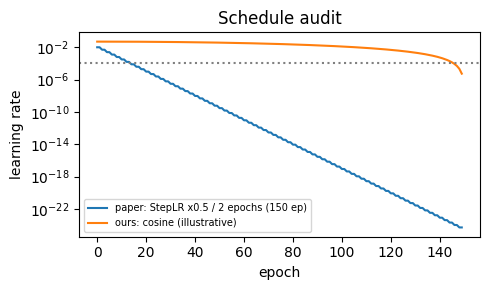

Under the paper's schedule the learning rate drops below 1e-4 at epoch 14; it is 5.29e-25 at epoch 150.


In [24]:
E = 150
ep = np.arange(E)
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(ep, [0.01 * 0.5 ** (e // 2) for e in ep], label="paper: StepLR x0.5 / 2 epochs (150 ep)")
ax.semilogy(ep, [0.5 * 0.05 * (1 + math.cos(math.pi * e / E)) + 1e-12 for e in ep], label="ours: cosine (illustrative)")
ax.axhline(1e-4, color="gray", ls=":"); ax.set_xlabel("epoch"); ax.set_ylabel("learning rate"); ax.legend(fontsize=7); ax.set_title("Schedule audit")
plt.tight_layout(); plt.savefig(OUT / "figures" / "lr_schedule.pdf"); plt.show()
first = next(e for e in ep if 0.01 * 0.5 ** (e // 2) < 1e-4)
print(f"Under the paper's schedule the learning rate drops below 1e-4 at epoch {first}; it is {0.01*0.5**(149//2):.2e} at epoch 150.")

### 1.3 Reproduction runs (paper protocol)
**What:** train every baseline and LoTAS exactly as the paper describes (no BN for baselines, BN-after-activation for LoTAS). `lotas_nobn` is added to isolate the BN effect.
**Why:** Stage 1 asks "can the paper's claim be reproduced?" - we need these numbers before proposing anything.

In [25]:
PAPER_ACTS = CFG["baselines"] + ["lotas", "lotas_nobn"]
run_grid(CFG["datasets"], "paper", CFG["archs"], PAPER_ACTS, CFG["seeds"])

[  1/30] cifar10 | paper | simplecnn | relu           | seed 0 -> acc=77.41 f1=77.41 
[  2/30] cifar10 | paper | simplecnn | relu           | seed 1 -> acc=77.04 f1=77.02 
[  3/30] cifar10 | paper | simplecnn | relu           | seed 2 -> acc=77.34 f1=77.29 
[  4/30] cifar10 | paper | simplecnn | leaky_relu     | seed 0 -> acc=77.93 f1=77.93 
[  5/30] cifar10 | paper | simplecnn | leaky_relu     | seed 1 -> acc=77.27 f1=77.24 
[  6/30] cifar10 | paper | simplecnn | leaky_relu     | seed 2 -> acc=77.30 f1=77.28 
[ 10/30] cifar10 | paper | simplecnn | elu            | seed 0 -> acc=78.97 f1=78.96 
[ 11/30] cifar10 | paper | simplecnn | elu            | seed 1 -> acc=78.80 f1=78.81 
[ 12/30] cifar10 | paper | simplecnn | elu            | seed 2 -> acc=79.10 f1=79.10 
[ 13/30] cifar10 | paper | simplecnn | gelu           | seed 0 -> acc=70.35 f1=70.30 
[ 14/30] cifar10 | paper | simplecnn | gelu           | seed 1 -> acc=69.86 f1=69.80 
[ 15/30] cifar10 | paper | simplecnn | gelu           

### 1.4 Reproduction table: paper-reported vs ours
**What:** compare with the numbers the paper reports (CIFAR-10, Table V: SimpleCNN and VGG-11). Reported values are copied from the paper; ours come from `results/runs`.
**How to read it:** exact equality is not expected (the paper does not define its architectures). The **ranking and the size of the LoTAS margin** are what we reproduce.

In [26]:
PAPER_TABLE_V = {   # CIFAR-10, accuracy % as printed in the base paper (Table V)
 "simplecnn": {"lotas":74.21,"elu":70.17,"relu":69.93,"prelu":69.91,"leaky_relu":69.84,"mish":68.69,"gelu":68.09,"silu":65.90},
 "vgg11":     {"lotas":80.82,"elu":73.46,"prelu":67.50,"relu":64.10,"leaky_relu":61.08},
}
def load_runs():
    rows = []
    for f in sorted((OUT / "runs").glob("*.json")):
        r = json.load(open(f)); r["learned_n"] = len(r.get("learned", [])); rows.append(r)
    return pd.DataFrame(rows)

def reproduction_table(ds="cifar10"):
    df = load_runs()
    if df.empty: print("no runs yet"); return None
    df = df[(df.protocol == "paper") & (df.dataset == ds)]
    g = df.groupby(["arch", "act"]).acc.agg(["mean", "std", "count"]).reset_index()
    g["paper_reported"] = [PAPER_TABLE_V.get(a, {}).get(c, np.nan) for a, c in zip(g.arch, g.act)]
    g["act"] = g.act.map(lambda a: LABEL.get(a, a)); return g.round(2)
rep = reproduction_table(); display(rep)

,arch,act,mean,std,count,paper_reported
0,simplecnn,ELU,78.96,0.15,3,70.17
1,simplecnn,GELU,70.10,0.25,3,68.09
2,simplecnn,Leaky ReLU,77.50,0.37,3,69.84
3,simplecnn,LoTAS (paper),80.13,0.03,3,74.21
4,simplecnn,"LoTAS (paper, no BN)",77.51,0.27,3,NaN
5,simplecnn,Mish,74.75,0.24,3,68.69
6,simplecnn,PReLU,77.48,0.20,3,69.91
7,simplecnn,ReLU,77.26,0.20,3,69.93
8,simplecnn,Serf,76.71,0.28,3,NaN
9,simplecnn,SiLU/Swish,66.58,0.32,3,65.90


## Stage 2 - Baseline activation benchmark (fair protocol)
**What:** the same eight baselines **plus the paper's LoTAS** with *identical* BN placement (Conv -> BN -> Act), the same optimiser, same schedule, same augmentation.
**Why:** this is the benchmark any new activation must beat. Differences now come from the activation only.

In [27]:
run_grid(CFG["datasets"], "fair_bn", CFG["archs"], CFG["baselines"] + ["lotas"], CFG["seeds"])

[  1/27] cifar10 | fair_bn | simplecnn | relu           | seed 0 -> acc=89.63 f1=89.61 
[  2/27] cifar10 | fair_bn | simplecnn | relu           | seed 1 -> acc=89.99 f1=89.98 
[  3/27] cifar10 | fair_bn | simplecnn | relu           | seed 2 -> acc=90.02 f1=89.99 
[  4/27] cifar10 | fair_bn | simplecnn | leaky_relu     | seed 0 -> acc=89.94 f1=89.93 
[  5/27] cifar10 | fair_bn | simplecnn | leaky_relu     | seed 1 -> acc=90.00 f1=89.98 
[  6/27] cifar10 | fair_bn | simplecnn | leaky_relu     | seed 2 -> acc=89.91 f1=89.89 
[  7/27] cifar10 | fair_bn | simplecnn | prelu          | seed 0 -> acc=89.77 f1=89.76 
[  8/27] cifar10 | fair_bn | simplecnn | prelu          | seed 1 -> acc=89.87 f1=89.85 
[  9/27] cifar10 | fair_bn | simplecnn | prelu          | seed 2 -> acc=90.22 f1=90.21 
[ 10/27] cifar10 | fair_bn | simplecnn | elu            | seed 0 -> acc=88.54 f1=88.50 
[ 11/27] cifar10 | fair_bn | simplecnn | elu            | seed 1 -> acc=88.66 f1=88.64 
[ 12/27] cifar10 | fair_bn | sim

## Stage 3 - Proposed activation: **SLoTAS** (Smooth, Slope-bounded LoTAS)

### 3.1 Design (each piece answers one limitation)
$$\mathrm{SLoTAS}(x)=x\Big(\gamma+(1-\gamma)\,h(u)\,\sigma(\beta x)\Big),\qquad u=(x^{2}+\varepsilon)^{\alpha/2},\quad h(u)=\tanh\!\big(\ln(1+u)\big)=\frac{u(u+2)}{u^{2}+2u+2}$$
with $\alpha=\mathrm{softplus}(a)>0,\ \beta=\mathrm{softplus}(b)>0,\ \gamma=\mathrm{sigmoid}(c)\in(0,1)$, one scalar triple **per layer**, all trainable. Initialisation $(\alpha,\beta,\gamma)=(1,1.5,0.25)$.

| Change vs LoTAS | Limitation fixed | Consequence |
|---|---|---|
| **Convex mix** $\gamma+(1-\gamma)(\cdot)$ instead of additive $+\gamma x$ | L7 | slope multiplier $m(x)\in[\gamma,1)$: right tail slope $\to 1$ (ReLU-like, scale preserved), left tail slope $\to\gamma$ (learnable leak, never dead). LoTAS has slopes $1+\gamma$ and $\gamma$. |
| **Smooth absolute value** $\sqrt{x^2+\varepsilon}$ | L8 | $C^\infty$ (LoTAS is not $C^2$); gradients w.r.t. $\alpha$ stay finite at $x=0$ |
| **Softplus / sigmoid reparametrisation** | L6, L8 | $\alpha,\beta,\gamma$ always valid and trainable, one clear specification, nothing frozen "for stability" |
| **Rational form of $\tanh\ln(1+u)$** | L9 | $\tanh(\ln t)=(t^2-1)/(t^2+1)$, so no `log`/`tanh` calls are needed for this term |
| No dependence on BN inside the function | L1 | evaluated with identical BN placement for all activations |

**Derivative.** With $m(x)=\gamma+(1-\gamma)\,g(x)$, $g=h(u)\sigma(\beta x)$: $\ \mathrm{SLoTAS}'(x)=m(x)+x\,m'(x)$, where $m'(x)=(1-\gamma)\big[h'(u)\,u'(x)\,\sigma(\beta x)+h(u)\,\beta\,\sigma(\beta x)(1-\sigma(\beta x))\big]$, $u'(x)=\alpha\,x\,(x^2+\varepsilon)^{\alpha/2-1}$, $h'(u)=\dfrac{4(u+1)}{(u^2+2u+2)^2}$. (Verified numerically below against automatic differentiation.)

**Honest note on novelty:** the family "$x\cdot s(x)+\gamma x$" already exists (e.g. Tangma, Golwala 2025) and the base paper belongs to it. Novelty claimed here is the *specific slope-bounded, smooth, fully-trainable design* and the evidence that it helps; **do a Google Scholar / arXiv check before submission** and let the ablations show which part actually contributes.

### 3.2 Numerical verification of the maths
**What:** (a) the rational identity, (b) the closed-form derivative vs autodiff, (c) finite gradients w.r.t. alpha, beta, gamma at x = 0.
**Why:** a function proposed in a paper must be shown to behave exactly as its formulas say.

In [28]:
x = tf.constant(np.linspace(-20, 20, 40001), tf.float32)
u = tf.pow(tf.sqrt(x * x + 1e-4), 1.0)
err_identity = float(tf.reduce_max(tf.abs(tf.tanh(tf.math.log1p(u)) - u * (u + 2) / (u * u + 2 * u + 2))))
print(f"(a) max |tanh(log(1+u)) - u(u+2)/(u^2+2u+2)| = {err_identity:.2e}")

# (b) closed-form derivative vs autodiff (alpha=1, beta=1.5, gamma=0.25, eps=1e-4)
a_, b_, g_, eps_ = 1.0, 1.5, 0.25, 1e-4
def f_slotas(t): return SLoTAS(alpha0=a_, beta0=b_, gamma0=g_)(t)
with tf.GradientTape() as tp:
    tp.watch(x); y = f_slotas(x)
auto = tp.gradient(y, x)
u_  = (x * x + eps_) ** (a_ / 2); h_ = u_ * (u_ + 2) / (u_ * u_ + 2 * u_ + 2)
hp_ = 4 * (u_ + 1) / (u_ * u_ + 2 * u_ + 2) ** 2; up_ = a_ * x * (x * x + eps_) ** (a_ / 2 - 1)
sg  = tf.sigmoid(b_ * x); m_ = g_ + (1 - g_) * h_ * sg
mp_ = (1 - g_) * (hp_ * up_ * sg + h_ * b_ * sg * (1 - sg))
closed = m_ + x * mp_
print(f"(b) max |autodiff - closed-form derivative| = {float(tf.reduce_max(tf.abs(auto - closed))):.2e}")

# (c) gradients w.r.t. the three parameters at/near x = 0
layer = SLoTAS(); _ = layer(tf.zeros((1, 4)))
with tf.GradientTape() as tp:
    out = tf.reduce_sum(layer(tf.constant([[0.0, 1e-6, -1e-6, 0.5]])))
gr = tp.gradient(out, [layer.a, layer.b, layer.c])
print("(c) d out/d(a,b,c) at inputs including x=0:", [float(v) for v in gr], "| all finite:", all(np.isfinite(float(v)) for v in gr))

(a) max |tanh(log(1+u)) - u(u+2)/(u^2+2u+2)| = 2.98e-07
(b) max |autodiff - closed-form derivative| = 4.77e-07
(c) d out/d(a,b,c) at inputs including x=0: [-0.031688790768384933, 0.012209207750856876, 0.06925676763057709] | all finite: True


### 3.3 Shape and property analysis (answers "why might it help")
**What:** plot activation, first and second derivative for all functions, then compute: tail slopes, global minimum, monotonicity, **second-derivative jump at 0** (smoothness) and a **linearity index** (R^2 of a straight-line fit on [-3,3]; closer to 1 = closer to a linear map).
**Why:** these are properties of the *function itself*, independent of any dataset, so they support the explanation in the paper.

,Activation,slope_left,slope_right,min_value,monotonic,d2_jump_at_0,linearity_R2
0,ReLU,0.0000,1.0000,0.0000,True,0.0000,0.8000
1,Leaky ReLU,0.0100,1.0000,-0.0800,True,0.0000,0.8063
2,ELU,0.0003,1.0000,-0.9997,True,0.9990,0.9334
3,GELU,-0.0000,1.0000,-0.1700,False,0.0000,0.7669
4,SiLU/Swish,-0.0023,1.0023,-0.2785,False,0.0000,0.8050
5,Mish,-0.0023,1.0000,-0.3088,False,0.0002,0.8139
6,Serf,-0.0026,1.0000,-0.3484,False,0.0004,0.8238
7,LoTAS (paper),0.9494,2.0691,-8.1404,True,1.9970,0.9880
8,SLoTAS (ours),0.2500,1.0139,-2.0000,True,0.2209,0.9017


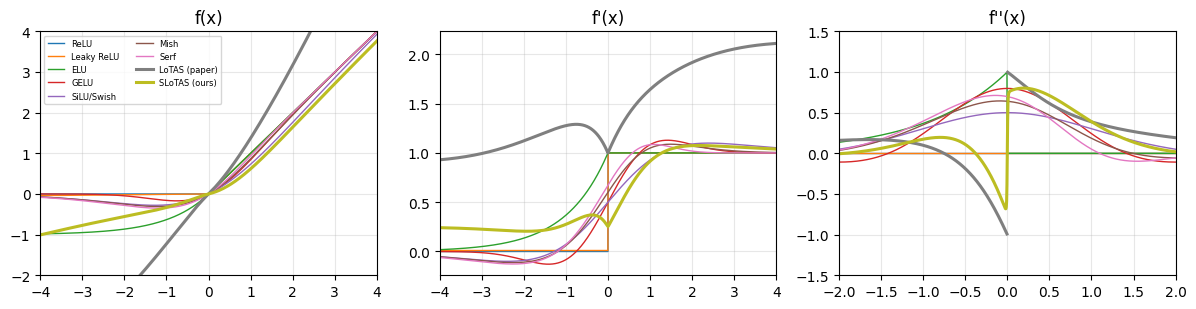

In [29]:
FUNCS = {n: make_act(n, 2) for n in ["relu","leaky_relu","elu","gelu","silu","mish","serf","lotas","slotas"]}
xs = tf.constant(np.linspace(-8, 8, 4001), tf.float32)

def f_d1_d2(layer, x):
    with tf.GradientTape() as t2:
        t2.watch(x)
        with tf.GradientTape() as t1:
            t1.watch(x); y = layer(x)
        d1 = t1.gradient(y, x)
    d2 = t2.gradient(d1, x)
    if d2 is None: d2 = tf.zeros_like(x)
    return y.numpy(), d1.numpy(), d2.numpy()

props, curves = [], {}
for n, L in FUNCS.items():
    y, d1, d2 = f_d1_d2(L, xs); curves[n] = (y, d1, d2)
    xp = tf.constant([-1e-3, 1e-3], tf.float32); _, _, d2z = f_d1_d2(L, xp)
    xl = np.linspace(-3, 3, 601); yl = L(tf.constant(xl, tf.float32)).numpy()
    A = np.vstack([xl, np.ones_like(xl)]).T; coef, res, *_ = np.linalg.lstsq(A, yl, rcond=None)
    r2 = 1 - ((yl - A @ coef) ** 2).sum() / ((yl - yl.mean()) ** 2).sum()
    props.append(dict(Activation=LABEL.get(n, n), slope_left=d1[0], slope_right=d1[-1], min_value=y.min(),
                      monotonic=bool((d1 >= -1e-6).all()), d2_jump_at_0=abs(float(d2z[1] - d2z[0])), linearity_R2=r2))
PROP = pd.DataFrame(props); display(PROP.round(4)); PROP.to_csv(OUT / "tables" / "properties.csv", index=False)

fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for n, (y, d1, d2) in curves.items():
    lw = 2.2 if n in ("lotas", "slotas") else 1.0
    axs[0].plot(xs.numpy(), y, lw=lw, label=LABEL[n]); axs[1].plot(xs.numpy(), d1, lw=lw); axs[2].plot(xs.numpy(), d2, lw=lw)
axs[0].set_xlim(-4, 4); axs[0].set_ylim(-2, 4); axs[1].set_xlim(-4, 4); axs[2].set_xlim(-2, 2); axs[2].set_ylim(-1.5, 1.5)
for a_, t in zip(axs, ["f(x)", "f'(x)", "f''(x)"]): a_.set_title(t); a_.grid(alpha=.3)
axs[0].legend(fontsize=6, ncol=2); plt.tight_layout(); plt.savefig(OUT / "figures" / "activation_shapes.pdf"); plt.show()

In [30]:
L = FUNCS["slotas"]  # Reuse the existing SLoTAS layer

deltas = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
rows = []

for delta in deltas:
    xp = tf.constant([-delta, 0.0, delta], dtype=tf.float32)
    y, d1, d2 = f_d1_d2(L, xp)

    rows.append({
        "delta": delta,
        "d2_left": float(d2[0]),
        "d2_at_zero": float(d2[1]),
        "d2_right": float(d2[2]),
        "left_right_difference": float(abs(d2[0] - d2[2])),
    })

D2_CHECK = pd.DataFrame(rows)
display(D2_CHECK)

,delta,d2_left,d2_at_zero,d2_right,left_right_difference
0,0.010000,-0.634959,0.005597,0.668372,1.303331
1,0.001000,-0.104684,0.005597,0.116210,0.220895
2,0.000100,-0.005538,0.005597,0.016735,0.022273
3,0.000010,0.004483,0.005597,0.006711,0.002228
4,0.000001,0.005486,0.005597,0.005708,0.000223


In [32]:
print("Layer dtype:", L64.dtype)
print("Variable dtypes:", [v.dtype for v in L64.weights])

for delta in [1e-3, 1e-5, 1e-7]:
    xp = tf.constant([-delta, 0.0, delta], dtype=tf.float64)

    with tf.GradientTape() as tape2:
        tape2.watch(xp)
        with tf.GradientTape() as tape1:
            tape1.watch(xp)
            y = L64(xp)
        d1 = tape1.gradient(y, xp)

    d2 = tape2.gradient(d1, xp)

    print(f"\ndelta = {delta:g}")
    print("Input dtype:", xp.dtype)
    print("Output dtype:", y.dtype)
    print("d2:", d2.numpy())

Layer dtype: float64
Variable dtypes: ['float64', 'float64', 'float64']

delta = 0.001
Input dtype: <dtype: 'float64'>
Output dtype: <dtype: 'float64'>
d2: [-0.10468447  0.00559688  0.11621024]

delta = 1e-05
Input dtype: <dtype: 'float64'>
Output dtype: <dtype: 'float64'>
d2: [0.00448314 0.00559688 0.00671064]

delta = 1e-07
Input dtype: <dtype: 'float64'>
Output dtype: <dtype: 'float64'>
d2: [0.00558574 0.00559688 0.00560801]


In [33]:
# Use the same float64 layer and fixed parameters.
x = tf.constant(
    np.linspace(-8, 8, 4001),
    dtype=tf.float64
)

alpha = tf.nn.softplus(L64.a)
beta  = tf.nn.softplus(L64.b)
gamma = tf.sigmoid(L64.c)
eps = tf.constant(1e-4, dtype=tf.float64)

with tf.GradientTape() as tape:
    tape.watch(x)
    y = L64(x)

d_auto = tape.gradient(y, x)

u = tf.pow(x * x + eps, alpha / 2.0)
h = u * (u + 2.0) / (u * u + 2.0 * u + 2.0)

hp = 4.0 * (u + 1.0) / tf.square(u * u + 2.0 * u + 2.0)
up = alpha * x * tf.pow(x * x + eps, alpha / 2.0 - 1.0)

s = tf.sigmoid(beta * x)
m = gamma + (1.0 - gamma) * h * s

mp = (1.0 - gamma) * (
    hp * up * s + h * beta * s * (1.0 - s)
)

d_closed = m + x * mp

max_error = tf.reduce_max(tf.abs(d_auto - d_closed))

print("Maximum absolute derivative error:", float(max_error.numpy()))
print("All autodiff values finite:", bool(tf.reduce_all(tf.math.is_finite(d_auto)).numpy()))
print("All closed-form values finite:", bool(tf.reduce_all(tf.math.is_finite(d_closed)).numpy()))

Maximum absolute derivative error: 8.881784197001252e-16
All autodiff values finite: True
All closed-form values finite: True


### 3.4 Computational cost (limitation L9)
**What:** forward+backward time of each activation on a tensor the size of one CNN feature map (64x32x32x64), plus number of activation parameters.
**Why:** the paper claims "marginally higher than ReLU" without measuring; a new paper must report cost.

In [34]:
def bench(name, iters=50):
    L = make_act(name, 4); x = tf.random.normal((8, 32, 32, 64) if SMOKE else (64, 32, 32, 64)); _ = L(x)
    @tf.function
    def step(x):
        with tf.GradientTape() as t:
            t.watch(x); y = tf.reduce_sum(L(x))
        return t.gradient(y, x)
    for _ in range(5): step(x)
    t0 = time.time()
    for _ in range(iters): g = step(x)
    _ = g.numpy(); return (time.time() - t0) / iters * 1000, int(sum(np.prod(w.shape) for w in L.trainable_weights))
_b = {n: bench(n) for n in ["relu","leaky_relu","elu","gelu","silu","mish","serf","lotas","slotas"]}
cost = pd.DataFrame([dict(Activation=LABEL[n], ms_fwd_bwd=v[0], extra_params=v[1]) for n, v in _b.items()])
cost["relative_to_relu"] = cost.ms_fwd_bwd / cost.ms_fwd_bwd.iloc[0]
display(cost.round(3)); cost.to_csv(OUT / "tables" / "cost.csv", index=False)

,Activation,ms_fwd_bwd,extra_params,relative_to_relu
0,ReLU,0.767,0,1.000
1,Leaky ReLU,0.643,0,0.838
2,ELU,0.831,0,1.083
3,GELU,2.623,0,3.420
4,SiLU/Swish,1.356,0,1.768
5,Mish,1.818,0,2.371
6,Serf,2.483,0,3.236
7,LoTAS (paper),4.876,1,6.356
8,SLoTAS (ours),8.135,3,10.604


In [35]:
print("TensorFlow version:", tf.__version__)
print("Visible GPUs:", tf.config.list_physical_devices("GPU"))
print("Visible CPUs:", tf.config.list_physical_devices("CPU"))
print("SMOKE:", SMOKE)
print("Input shape:", (8, 32, 32, 64) if SMOKE else (64, 32, 32, 64))
print("Tensor dtype:", tf.float32)

TensorFlow version: 2.20.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Visible CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
SMOKE: False
Input shape: (64, 32, 32, 64)
Tensor dtype: <dtype: 'float32'>


In [37]:
run_dir = OUT / "runs"

files = sorted(run_dir.glob("*.json"))

print("Total JSON result files:", len(files))

for path in files:
    print(path.name)

Total JSON result files: 57
cifar10_fair_bn_simplecnn_elu_s0.json
cifar10_fair_bn_simplecnn_elu_s1.json
cifar10_fair_bn_simplecnn_elu_s2.json
cifar10_fair_bn_simplecnn_gelu_s0.json
cifar10_fair_bn_simplecnn_gelu_s1.json
cifar10_fair_bn_simplecnn_gelu_s2.json
cifar10_fair_bn_simplecnn_leaky_relu_s0.json
cifar10_fair_bn_simplecnn_leaky_relu_s1.json
cifar10_fair_bn_simplecnn_leaky_relu_s2.json
cifar10_fair_bn_simplecnn_lotas_s0.json
cifar10_fair_bn_simplecnn_lotas_s1.json
cifar10_fair_bn_simplecnn_lotas_s2.json
cifar10_fair_bn_simplecnn_mish_s0.json
cifar10_fair_bn_simplecnn_mish_s1.json
cifar10_fair_bn_simplecnn_mish_s2.json
cifar10_fair_bn_simplecnn_prelu_s0.json
cifar10_fair_bn_simplecnn_prelu_s1.json
cifar10_fair_bn_simplecnn_prelu_s2.json
cifar10_fair_bn_simplecnn_relu_s0.json
cifar10_fair_bn_simplecnn_relu_s1.json
cifar10_fair_bn_simplecnn_relu_s2.json
cifar10_fair_bn_simplecnn_serf_s0.json
cifar10_fair_bn_simplecnn_serf_s1.json
cifar10_fair_bn_simplecnn_serf_s2.json
cifar10_fair_bn

In [39]:
print(protocol_cfg("paper", 30))
print(protocol_cfg("fair_bn", 30))

{'batch': 64, 'aug': False, 'lr0': 0.01, 'nesterov': False, 'sched': <function protocol_cfg.<locals>.<lambda> at 0x78e108a5b9c0>}
{'batch': 128, 'aug': True, 'lr0': 0.05, 'nesterov': True, 'sched': <function protocol_cfg.<locals>.<lambda> at 0x78e108a5b9c0>}


In [42]:
print("===== Learning-rate schedules =====")

paper_sched = protocol_cfg("paper", 30)["sched"]
fair_sched = protocol_cfg("fair_bn", 30)["sched"]

epochs_to_check = [0, 1, 2, 5, 10, 15, 20, 29]

print("Paper LR:")
print([float(paper_sched(e)) for e in epochs_to_check])

print("\nFair-BN LR:")
print([float(fair_sched(e)) for e in epochs_to_check])

===== Learning-rate schedules =====
Paper LR:
[0.01, 0.01, 0.005, 0.0025, 0.0003125, 7.8125e-05, 9.765625e-06, 6.103515625e-07]

Fair-BN LR:
[0.05, 0.049863047384206834, 0.049453690018345146, 0.046650635094610975, 0.037500000000000006, 0.02500000000000001, 0.012500000000000006, 0.000136952615793165]


### 3.5 Main SLoTAS runs and ablation
**What:** (i) SLoTAS in both main protocols. (ii) Ablations in `fair_bn`, each removing one design element: fixed parameters, no gate, no log-tanh (leaky-Swish), no leak (gamma ~ 0), hard |x|. LoTAS with learnable alpha, beta is included as the paper's own "learnable variant".
**Why:** the editor/reviewer question "*which part of the function actually matters?*" is answered here.

In [45]:

# Check the saved training history and model configuration
import json
import numpy as np

p = OUT / "runs" / "cifar10_paper_simplecnn_slotas_s0.json"
r = json.load(open(p))
h = r["history"]

for key in ["loss", "val_loss", "accuracy", "val_accuracy"]:
    values = np.asarray(h.get(key, []), dtype=float)
    if len(values):
        print(
            key,
            "| first 5:", np.round(values[:5], 4),
            "| last 5:", np.round(values[-5:], 4),
            "| finite:", np.isfinite(values).all()
        )

print("\nLearning-rate schedule:")
sched = protocol_cfg("paper", CFG["epochs"])["sched"]
print([float(sched(e)) for e in range(5)])

print("\nSaved run metadata:")
for key in ["epochs", "time_per_epoch", "n_params", "diverged"]:
    print(key, "=", r.get(key))


loss | first 5: [2.3501 2.347  2.3445 2.343  2.3418] | last 5: [2.3393 2.3393 2.3393 2.3393 2.3393] | finite: True
val_loss | first 5: [2.3484 2.3451 2.3436 2.3421 2.3414] | last 5: [2.3393 2.3393 2.3393 2.3393 2.3393] | finite: True
accuracy | first 5: [0.0974 0.0958 0.0975 0.0961 0.0969] | last 5: [0.1 0.1 0.1 0.1 0.1] | finite: True
val_accuracy | first 5: [0.1 0.1 0.1 0.1 0.1] | last 5: [0.1 0.1 0.1 0.1 0.1] | finite: True

Learning-rate schedule:
[0.01, 0.01, 0.005, 0.005, 0.0025]

Saved run metadata:
epochs = 30
time_per_epoch = 5.842458287874858
n_params = 666556
diverged = False


In [46]:

# Inspect the saved prediction distribution
import numpy as np
from collections import Counter

p = OUT / "runs" / "cifar10_paper_simplecnn_slotas_s0_pred.npy"

if p.exists():
    pred = np.load(p)
    print("Prediction shape:", pred.shape)
    print("Prediction counts:", Counter(pred.tolist()))
    print("Unique predicted classes:", np.unique(pred))
else:
    print("Prediction file not found.")


Prediction shape: (10000,)
Prediction counts: Counter({5: 10000})
Unique predicted classes: [5]


In [47]:

import tensorflow as tf
import numpy as np

layer = SLoTAS()
x = tf.constant([-3., -1., 0., 1., 3.], dtype=tf.float32)

with tf.GradientTape() as tape:
    tape.watch(x)
    y = layer(x)
    loss = tf.reduce_sum(y)

dx = tape.gradient(loss, x)

print("Input:", x.numpy())
print("Output:", y.numpy())
print("Input gradients:", dx.numpy())
print("Trainable variables:", [
    (v.name, v.numpy()) for v in layer.trainable_variables
])


Input: [-3. -1.  0.  1.  3.]
Output: [-0.7718123 -0.3320937  0.         0.6179184  2.7134838]
Input gradients: [0.22628035 0.27519464 0.25373125 0.9147922  1.0600505 ]
Trainable variables: [('a', np.float32(0.54132485)), ('b', np.float32(1.2475176)), ('c', np.float32(-1.0986123))]


In [48]:
# Inspect logits and predicted-class confidence on a small batch
d = get_data("cifar10")

model = build_model(
    "simplecnn",
    d["shape"],
    d["n_classes"],
    "slotas",
    "paper"
)

logits = model(d["xtr"][:16], training=False).numpy()

print("Logits shape:", logits.shape)
print("Logits finite:", np.isfinite(logits).all())
print("First 3 logits:\n", logits[:3])
print("Predicted classes:", logits.argmax(axis=1))
print("Logit std per image:", logits.std(axis=1))

Logits shape: (16, 10)
Logits finite: True
First 3 logits:
 [[-5.2413152e-06 -1.9256945e-06 -1.0050817e-05  9.3777999e-07
   5.0881808e-06  1.6652146e-05 -4.0598979e-07 -4.5257011e-06
  -6.2999352e-06 -3.4588629e-06]
 [ 4.5779434e-06 -4.7115762e-05  7.0466558e-06  1.2372212e-05
  -8.8626284e-06  1.4086795e-06 -7.7116028e-06  1.1392594e-05
  -2.5886209e-05 -2.1479431e-05]
 [-4.2209822e-06 -5.0557185e-07 -9.1703823e-06  4.2733982e-06
  -2.6061573e-06  9.6545427e-06 -4.5706201e-08 -1.6105851e-06
  -1.2429473e-07 -4.7578683e-06]]
Predicted classes: [5 3 5 5 5 5 6 7 3 3 5 3 5 6 7 5]
Logit std per image: [7.0713618e-06 1.8147764e-05 4.8721190e-06 1.1612832e-05 7.4820146e-06
 7.8757566e-06 8.9542609e-06 1.1100165e-05 1.2163354e-05 3.6315403e-06
 1.4801117e-05 1.5488717e-05 1.2057659e-05 1.1782925e-05 1.2704323e-05
 5.0002482e-06]


In [49]:
# Inspect layer outputs and weight scales
import numpy as np
import tensorflow as tf

d = get_data("cifar10")

model = build_model(
    "simplecnn",
    d["shape"],
    d["n_classes"],
    "slotas",
    "paper"
)

x = tf.convert_to_tensor(d["xtr"][:8])

print("Input range:", float(tf.reduce_min(x)),
      float(tf.reduce_max(x)))

for layer in model.layers:
    try:
        probe = keras.Model(model.inputs, layer.output)
        y = probe(x, training=False)
        y = tf.convert_to_tensor(y)

        weights = layer.trainable_weights
        weight_info = [
            (w.name, tuple(w.shape),
             float(tf.reduce_min(w)),
             float(tf.reduce_max(w)))
            for w in weights
        ]

        print(
            layer.name,
            "| output shape:", tuple(y.shape),
            "| output std:", float(tf.math.reduce_std(y)),
            "| weights:", weight_info
        )
    except Exception as e:
        print(layer.name, "| inspection issue:", str(e)[:160])

Input range: -1.9894300699234009 2.1262943744659424
input_layer_2 | output shape: (8, 32, 32, 3) | output std: 0.9847084283828735 | weights: []
conv2d_10 | output shape: (8, 32, 32, 32) | output std: 0.4683281183242798 | weights: [('kernel', (3, 3, 3, 32), -0.19244201481342316, 0.19135291874408722), ('bias', (32,), 0.0, 0.0)]
s_lo_tas_13 | output shape: (8, 32, 32, 32) | output std: 0.21543070673942566 | weights: [('a', (), 0.5413248538970947, 0.5413248538970947), ('b', (), 1.2475175857543945, 1.2475175857543945), ('c', (), -1.0986123085021973, -1.0986123085021973)]
conv2d_11 | output shape: (8, 32, 32, 32) | output std: 0.11544594168663025 | weights: [('kernel', (3, 3, 32, 32), -0.05892309173941612, 0.05889686569571495), ('bias', (32,), 0.0, 0.0)]
s_lo_tas_14 | output shape: (8, 32, 32, 32) | output std: 0.03842104971408844 | weights: [('a', (), 0.5413248538970947, 0.5413248538970947), ('b', (), 1.2475175857543945, 1.2475175857543945), ('c', (), -1.0986123085021973, -1.098612308502197

In [50]:
import tensorflow as tf
import numpy as np

layer = SLoTAS()
x = tf.linspace(-3.0, 3.0, 2001)

with tf.GradientTape() as tape:
    tape.watch(x)
    y = layer(x)

dy_dx = tape.gradient(y, x).numpy()

print("Output std:", float(tf.math.reduce_std(y)))
print("Derivative min:", float(np.min(dy_dx)))
print("Derivative max:", float(np.max(dy_dx)))
print("Derivative mean abs:", float(np.mean(np.abs(dy_dx))))
print("Derivative finite:", bool(np.isfinite(dy_dx).all()))

Output std: 1.0098512172698975
Derivative min: 0.20545849204063416
Derivative max: 1.0756993293762207
Derivative mean abs: 0.5809138417243958
Derivative finite: True


In [51]:
import tensorflow as tf
import numpy as np

d = get_data("cifar10")
keras.utils.set_random_seed(123)

model = build_model(
    "simplecnn",
    d["shape"],
    d["n_classes"],
    "slotas",
    "paper"
)

x = tf.convert_to_tensor(d["xtr"][:64])
y = tf.convert_to_tensor(d["ytr"][:64])

with tf.GradientTape() as tape:
    logits = model(x, training=True)
    loss = keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )(y, logits)

grads = tape.gradient(loss, model.trainable_variables)

print("Loss:", float(loss))
print("Logits std:", float(tf.math.reduce_std(logits)))
print("Finite logits:", bool(tf.reduce_all(tf.math.is_finite(logits))))

for v, g in zip(model.trainable_variables, grads):
    if g is None:
        print(v.name, "| gradient=None")
    else:
        print(
            v.name,
            "| weight std:", float(tf.math.reduce_std(v)),
            "| grad norm:", float(tf.linalg.global_norm([g])),
            "| finite:", bool(tf.reduce_all(tf.math.is_finite(g)))
        )

Loss: 2.302586555480957
Logits std: 1.0383576409367379e-05
Finite logits: True
kernel | weight std: 0.11031525582075119 | grad norm: 1.3906209460401442e-05 | finite: True
bias | weight std: 0.0 | grad norm: 1.8034922959486721e-06 | finite: True
a | weight std: 0.0 | grad norm: 1.6892121834644058e-07 | finite: True
b | weight std: 0.0 | grad norm: 1.036672827581242e-07 | finite: True
c | weight std: 0.0 | grad norm: 8.995206712825166e-07 | finite: True
kernel | weight std: 0.033813126385211945 | grad norm: 3.4774373489199206e-05 | finite: True
bias | weight std: 0.0 | grad norm: 7.37057052901946e-06 | finite: True
a | weight std: 0.0 | grad norm: 2.79296955341124e-07 | finite: True
b | weight std: 0.0 | grad norm: 4.2533475408390586e-08 | finite: True
c | weight std: 0.0 | grad norm: 8.275812888314249e-07 | finite: True
kernel | weight std: 0.03395388647913933 | grad norm: 4.0279326640302315e-05 | finite: True
bias | weight std: 0.0 | grad norm: 4.3053463741671294e-05 | finite: True
a |

In [52]:
run_grid(
    ["cifar10"],
    "fair_bn",
    ["simplecnn"],
    ["slotas"],
    [0, 1, 2]
)

[  1/3] cifar10 | fair_bn | simplecnn | slotas         | seed 0 -> acc=89.94 f1=89.93 
[  2/3] cifar10 | fair_bn | simplecnn | slotas         | seed 1 -> acc=90.11 f1=90.11 
[  3/3] cifar10 | fair_bn | simplecnn | slotas         | seed 2 -> acc=89.90 f1=89.89 
Grid finished in 9.5 min


In [53]:
run_grid(
    ["cifar10"],
    "fair_bn",
    ["simplecnn"],
    [
        "slotas_fixed",
        "slotas_nogate",
        "slotas_nolog",
        "slotas_noleak",
        "slotas_hardabs"
    ],
    [0, 1, 2]
)

[  1/15] cifar10 | fair_bn | simplecnn | slotas_fixed   | seed 0 -> acc=89.15 f1=89.12 
[  2/15] cifar10 | fair_bn | simplecnn | slotas_fixed   | seed 1 -> acc=89.29 f1=89.26 
[  3/15] cifar10 | fair_bn | simplecnn | slotas_fixed   | seed 2 -> acc=89.34 f1=89.32 
[  4/15] cifar10 | fair_bn | simplecnn | slotas_nogate  | seed 0 -> acc=87.87 f1=87.84 
[  5/15] cifar10 | fair_bn | simplecnn | slotas_nogate  | seed 1 -> acc=87.42 f1=87.39 
[  6/15] cifar10 | fair_bn | simplecnn | slotas_nogate  | seed 2 -> acc=88.02 f1=88.00 
[  7/15] cifar10 | fair_bn | simplecnn | slotas_nolog   | seed 0 -> acc=89.73 f1=89.72 
[  8/15] cifar10 | fair_bn | simplecnn | slotas_nolog   | seed 1 -> acc=90.30 f1=90.29 
[  9/15] cifar10 | fair_bn | simplecnn | slotas_nolog   | seed 2 -> acc=90.12 f1=90.11 
[ 10/15] cifar10 | fair_bn | simplecnn | slotas_noleak  | seed 0 -> acc=89.91 f1=89.91 
[ 11/15] cifar10 | fair_bn | simplecnn | slotas_noleak  | seed 1 -> acc=90.05 f1=90.04 
[ 12/15] cifar10 | fair_bn | sim

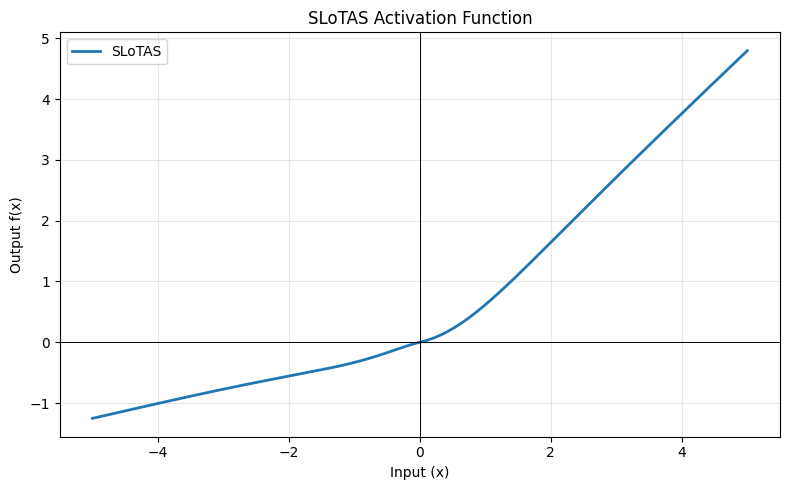

In [54]:
import numpy as np
import matplotlib.pyplot as plt

# SLoTAS initial parameters
alpha = 1.0
beta = 1.5
gamma = 0.25
eps = 1e-4

def slotas(x, alpha=alpha, beta=beta,
           gamma=gamma, eps=eps):

    absx = np.sqrt(x**2 + eps)
    u = absx**alpha

    h = (u * (u + 2)) / (u**2 + 2*u + 2)

    sigmoid = 1 / (1 + np.exp(-np.clip(beta*x, -500, 500)))

    return x * (gamma + (1-gamma)*h*sigmoid)


x = np.linspace(-5, 5, 1000)
y = slotas(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y, label="SLoTAS", linewidth=2)
plt.axhline(0, color="black", linewidth=0.7)
plt.axvline(0, color="black", linewidth=0.7)
plt.xlabel("Input (x)")
plt.ylabel("Output f(x)")
plt.title("SLoTAS Activation Function")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Fig1_SLoTAS_Activation.png", dpi=300)
plt.show()

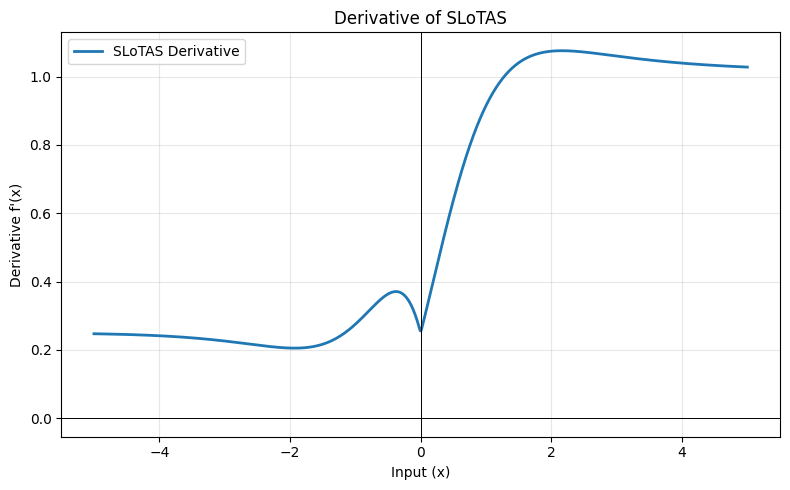

Minimum derivative: 0.20546006247235837
Maximum derivative: 1.0756969599270718


In [55]:
# Numerical derivative of SLoTAS
x = np.linspace(-5, 5, 1000)
y = slotas(x)

dy_dx = np.gradient(y, x)

plt.figure(figsize=(8, 5))
plt.plot(x, dy_dx, label="SLoTAS Derivative",
         linewidth=2)

plt.axhline(0, color="black", linewidth=0.7)
plt.axvline(0, color="black", linewidth=0.7)

plt.xlabel("Input (x)")
plt.ylabel("Derivative f'(x)")
plt.title("Derivative of SLoTAS")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Fig2_SLoTAS_Derivative.png", dpi=300)
plt.show()

print("Minimum derivative:", dy_dx.min())
print("Maximum derivative:", dy_dx.max())

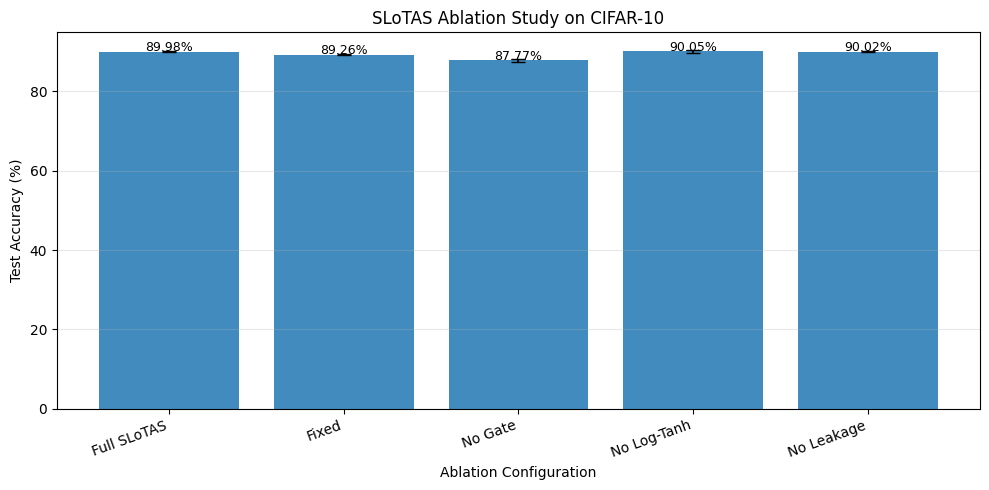

In [56]:
import numpy as np
import matplotlib.pyplot as plt

ablation = {
    "Full SLoTAS": [89.94, 90.11, 89.90],
    "Fixed":       [89.15, 89.29, 89.34],
    "No Gate":     [87.87, 87.42, 88.02],
    "No Log-Tanh": [89.73, 90.30, 90.12],
    "No Leakage":  [89.91, 90.05, 90.09]
}

names = list(ablation.keys())
means = [np.mean(ablation[k]) for k in names]
stds = [np.std(ablation[k], ddof=1) for k in names]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    names, means,
    yerr=stds,
    capsize=5,
    alpha=0.85
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Ablation Configuration")
plt.title("SLoTAS Ablation Study on CIFAR-10")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar, mean in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.12,
        f"{mean:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig("Fig3_SLoTAS_Ablation.png", dpi=300)
plt.show()

In [57]:
import os

base = "/kaggle/working"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        path = os.path.join(root, file)
        size = os.path.getsize(path) / 1024
        print(f"{indent}  {file} ({size:.2f} KB)")

working/
  Fig2_SLoTAS_Derivative.png (98.46 KB)
  Fig3_SLoTAS_Ablation.png (142.06 KB)
  Fig1_SLoTAS_Activation.png (89.41 KB)
  results/
    figures/
      activation_shapes.pdf (23.95 KB)
      lr_schedule.pdf (15.24 KB)
    runs/
      cifar10_paper_simplecnn_mish_s2.json (3.62 KB)
      cifar10_fair_bn_simplecnn_elu_s0_pred.npy (19.66 KB)
      cifar10_paper_simplecnn_gelu_s2.json (3.58 KB)
      cifar10_paper_simplecnn_slotas_s0_pred.npy (19.66 KB)
      cifar10_paper_simplecnn_mish_s0_pred.npy (19.66 KB)
      cifar10_paper_simplecnn_leaky_relu_s1.json (3.61 KB)
      cifar10_paper_simplecnn_mish_s2_pred.npy (19.66 KB)
      cifar10_fair_bn_simplecnn_serf_s0.json (3.55 KB)
      cifar10_fair_bn_simplecnn_lotas_s1_pred.npy (19.66 KB)
      cifar10_paper_simplecnn_leaky_relu_s1_pred.npy (19.66 KB)
      cifar10_fair_bn_simplecnn_prelu_s2.json (3.52 KB)
      cifar10_paper_simplecnn_serf_s2.json (3.60 KB)
      cifar10_paper_simplecnn_leaky_relu_s2.json (3.60 KB)
      cifar10_fair

In [58]:
import json
import pandas as pd
import numpy as np
from pathlib import Path

run_dir = Path("/kaggle/working/results/runs")

records = []

for path in sorted(run_dir.glob("*.json")):
    with open(path) as f:
        r = json.load(f)

    records.append({
        "file": path.name,
        "protocol": r.get("protocol"),
        "activation": r.get("act"),
        "seed": r.get("seed"),
        "diverged": r.get("diverged"),
        "accuracy": r.get("acc"),
        "macro_f1": r.get("macro_f1"),
        "auc": r.get("auc"),
        "test_loss": r.get("test_loss"),
        "ece": r.get("ece"),
        "grad_mean": r.get("grad_mean"),
        "grad_zero_pct": r.get("grad_zero_pct"),
        "per_class_recall": r.get("per_class_recall"),
        "time_per_epoch": r.get("time_per_epoch"),
        "n_params": r.get("n_params"),
        "learned": r.get("learned")
    })

df = pd.DataFrame(records)

print("Total JSON files:", len(df))
print("\nMissing values:")
print(df.isnull().sum())

print("\nFair-BN results:")
display(
    df[df["protocol"] == "fair_bn"]
    [["activation", "seed", "diverged", "accuracy",
      "macro_f1", "auc", "test_loss", "ece"]]
    .sort_values(["activation", "seed"])
)

print("\nFair-BN summary:")
summary = (
    df[df["protocol"] == "fair_bn"]
    .groupby("activation")
    [["accuracy", "macro_f1", "auc", "test_loss", "ece",
      "grad_mean", "grad_zero_pct", "time_per_epoch"]]
    .agg(["mean", "std", "count"])
)

display(summary.round(4))

Total JSON files: 76

Missing values:
file                0
protocol            0
activation          0
seed                0
diverged            0
accuracy            0
macro_f1            0
auc                 0
test_loss           0
ece                 0
grad_mean           3
grad_zero_pct       0
per_class_recall    0
time_per_epoch      0
n_params            0
learned             0
dtype: int64

Fair-BN results:


,activation,seed,diverged,accuracy,macro_f1,auc,test_loss,ece
0,elu,0,False,88.54,88.500481,99.192639,0.344987,1.629971e+00
1,elu,1,False,88.66,88.642367,99.250501,0.329257,1.343052e+00
2,elu,2,False,88.84,88.813650,99.242812,0.332172,1.430452e+00
3,gelu,0,False,90.54,90.516952,99.448824,0.290159,2.326768e+00
4,gelu,1,False,90.29,90.278084,99.402130,0.306264,2.664938e+00
5,gelu,2,False,90.40,90.372494,99.413575,0.298480,2.536591e+00
6,leaky_relu,0,False,89.94,89.925520,99.350613,0.312862,2.489703e+00
7,leaky_relu,1,False,90.00,89.982593,99.392399,0.299413,1.963582e+00
8,leaky_relu,2,False,89.91,89.891806,99.333787,0.313936,2.154357e+00
9,lotas,0,False,89.11,89.075982,99.288371,0.336388,3.270774e+00



Fair-BN summary:


accuracy               macro_f1                    auc          \
                   mean     std count     mean     std count     mean     std   
activation                                                                      
elu             88.6800  0.1510     3  88.6522  0.1568     3  99.2287  0.0314   
gelu            90.4100  0.1253     3  90.3892  0.1203     3  99.4215  0.0243   
leaky_relu      89.9500  0.0458     3  89.9333  0.0459     3  99.3589  0.0302   
lotas           89.1800  0.1758     3  89.1594  0.1866     3  99.2790  0.0136   
mish            90.1967  0.0404     3  90.1754  0.0477     3  99.4001  0.0167   
prelu           89.9533  0.2363     3  89.9416  0.2396     3  99.3678  0.0279   
relu            89.8800  0.2170     3  89.8621  0.2156     3  99.3503  0.0253   
serf            90.0333  0.1258     3  90.0162  0.1195     3  99.3923  0.0261   
silu            90.2700  0.2107     3  90.2543  0.2023     3  99.4090  0.0276   
slotas          89.9833  0.1115     3  89.9755  0.1140     3  99.3832  0.0119   
slotas_fixed    89.2600  0.0985     3  89.2340  0.1057     3  99.2977  0.0106   
slotas_hardabs  10.0000  0.0000     3   1.8182  0.0000     3  50.0000  0.0000   
slotas_nogate   87.7700  0.3122     3  87.7414  0.3173     3  99.0987  0.0325   
slotas_noleak   90.0167  0.0945     3  90.0076  0.0917     3  99.3938  0.0110   
slotas_nolog    90.0500  0.2914     3  90.0395  0.2882     3  99.3937  0.0116   

                     test_loss  ...   ece grad_mean                \
               count      mean  ... count      mean     std count   
activation                      ...                                 
elu                3    0.3355  ...     3    0.0008  0.0000     3   
gelu               3    0.2983  ...     3    0.0007  0.0001     3   
leaky_relu         3    0.3087  ...     3    0.0007  0.0000     3   
lotas              3    0.3365  ...     3    0.0009  0.0002     3   
mish               3    0.3004  ...     3    0.0006  0.0000     3   
prelu              3    0.3115  ...     3    0.0010  0.0000     3   
relu               3    0.3121  ...     3    0.0008  0.0001     3   
serf               3    0.3010  ...     3    0.0006  0.0000     3   
silu               3    0.2970  ...     3    0.0007  0.0000     3   
slotas             3    0.3105  ...     3    0.0007  0.0001     3   
slotas_fixed       3    0.3216  ...     3    0.0008  0.0000     3   
slotas_hardabs     3    2.3026  ...     3       NaN     NaN     0   
slotas_nogate      3    0.3667  ...     3    0.0007  0.0000     3   
slotas_noleak      3    0.3061  ...     3    0.0006  0.0001     3   
slotas_nolog       3    0.3037  ...     3    0.0006  0.0001     3   

               grad_zero_pct            time_per_epoch                
                        mean  std count           mean     std count  
activation                                                            
elu                      0.0  0.0     3         5.0962  0.0032     3  
gelu                     0.0  0.0     3         5.2568  0.0068     3  
leaky_relu               0.0  0.0     3         4.7712  0.0065     3  
lotas                    0.0  0.0     3         5.6455  0.0152     3  
mish                     0.0  0.0     3         5.2186  0.0056     3  
prelu                    0.0  0.0     3         5.1181  0.0079     3  
relu                     0.0  0.0     3         4.7687  0.0837     3  
serf                     0.0  0.0     3         5.0576  0.0072     3  
silu                     0.0  0.0     3         4.6871  0.0047     3  
slotas                   0.0  0.0     3         6.1529  0.0847     3  
slotas_fixed             0.0  0.0     3         5.2666  0.0512     3  
slotas_hardabs           0.0  0.0     3        12.2345  0.1884     3  
slotas_nogate            0.0  0.0     3         6.0545  0.0036     3  
slotas_noleak            0.0  0.0     3         6.0283  0.0022     3  
slotas_nolog             0.0  0.0     3         5.5930  0.0013     3  

[15 rows x 24 columns]

In [59]:
slotas = df[
    (df["protocol"] == "fair_bn") &
    (df["activation"] == "slotas")
]

for _, row in slotas.iterrows():
    print(f"\nSeed: {row['seed']}")

    for i, params in enumerate(row["learned"]):
        print(
            f"Layer {i+1}: "
            f"alpha={params['alpha']:.6f}, "
            f"beta={params['beta']:.6f}, "
            f"gamma={params['gamma']:.6f}"
        )


Seed: 0
Layer 1: alpha=0.140808, beta=2.384834, gamma=0.049113
Layer 2: alpha=3.098131, beta=2.474412, gamma=0.042748
Layer 3: alpha=1.535299, beta=2.550174, gamma=0.009945
Layer 4: alpha=2.230191, beta=2.262152, gamma=0.018465
Layer 5: alpha=2.421884, beta=2.088636, gamma=0.009016
Layer 6: alpha=3.141276, beta=3.154613, gamma=0.007798

Seed: 1
Layer 1: alpha=0.164657, beta=2.385080, gamma=0.066763
Layer 2: alpha=3.222755, beta=2.533630, gamma=0.041094
Layer 3: alpha=1.747228, beta=2.632752, gamma=0.009730
Layer 4: alpha=2.221465, beta=2.224803, gamma=0.017715
Layer 5: alpha=2.379612, beta=2.018748, gamma=0.009562
Layer 6: alpha=3.175733, beta=3.175230, gamma=0.007854

Seed: 2
Layer 1: alpha=0.143144, beta=2.362423, gamma=0.077618
Layer 2: alpha=3.109730, beta=2.537801, gamma=0.036580
Layer 3: alpha=1.383079, beta=2.498164, gamma=0.010153
Layer 4: alpha=2.179407, beta=2.240907, gamma=0.016852
Layer 5: alpha=2.326874, beta=2.009588, gamma=0.009407
Layer 6: alpha=3.236690, beta=3.185151

In [60]:
import json
from pathlib import Path
from pprint import pprint

run_dir = Path("/kaggle/working/results/runs")

files = [
    "cifar10_fair_bn_simplecnn_slotas_s0.json",
    "cifar10_fair_bn_simplecnn_gelu_s0.json",
    "cifar10_fair_bn_simplecnn_slotas_nogate_s0.json"
]

for filename in files:
    path = run_dir / filename

    print("\n" + "=" * 70)
    print(filename)

    with open(path) as f:
        data = json.load(f)

    print("Available keys:")
    print(list(data.keys()))

    print("\nMetrics and saved parameter information:")
    for key in [
        "acc", "macro_f1", "auc", "test_loss",
        "ece", "per_class_recall",
        "grad_mean", "grad_zero_pct",
        "learned", "diverged"
    ]:
        print(f"\n{key}:")
        pprint(data.get(key))


cifar10_fair_bn_simplecnn_slotas_s0.json
Available keys:
['dataset', 'protocol', 'arch', 'act', 'seed', 'epochs', 'diverged', 'acc', 'macro_f1', 'auc', 'test_loss', 'ece', 'grad_mean', 'grad_zero_pct', 'per_class_recall', 'time_per_epoch', 'n_params', 'learned', 'history']

Metrics and saved parameter information:

acc:
89.94

macro_f1:
89.92881860097708

auc:
99.39676666666666

test_loss:
0.30655670166015625

ece:
2.7789154785871517

per_class_recall:
[92.4,
 96.5,
 84.39999999999999,
 79.5,
 89.4,
 83.8,
 93.5,
 92.10000000000001,
 93.60000000000001,
 94.19999999999999]

grad_mean:
0.0005773651064373553

grad_zero_pct:
0.0

learned:
[{'alpha': 0.14080819487571716,
  'beta': 2.384833574295044,
  'gamma': 0.04911310598254204},
 {'alpha': 3.098130941390991,
  'beta': 2.474412202835083,
  'gamma': 0.04274832457304001},
 {'alpha': 1.5352990627288818,
  'beta': 2.5501744747161865,
  'gamma': 0.00994494091719389},
 {'alpha': 2.230191230773926,
  'beta': 2.2621517181396484,
  'gamma': 0.018

In [ ]:
run_grid(CFG["datasets"], "paper",   CFG["archs"], ["slotas"], CFG["seeds"])
run_grid(CFG["datasets"], "fair_bn", CFG["archs"], ["slotas"] + CFG["ablations"] + ["lotas_learnall"], CFG["seeds"])

In [ ]:
# optional stress test without any normalisation 
RUN_NOBN = False
if RUN_NOBN:
    run_grid(CFG["datasets"], "fair_nobn", CFG["archs"], CFG["baselines"] + ["lotas", "slotas"], CFG["seeds"])

In [ ]:
# optional: extra datasets / architectures 
EXTRA = False
if EXTRA:
    for ds in ["cifar100", "mnist"]:
        verify_data(ds)
        run_grid([ds], "fair_bn", CFG["archs"], CFG["baselines"] + ["lotas", "slotas"], CFG["seeds"])

## Stage 4 - Evaluation
**What:** aggregate all finished runs; report **accuracy, macro-F1, AUC (macro one-vs-rest), test loss, ECE, per-class recall, gradient diagnostics, time per epoch**, as **mean +- std over seeds**. Diverged runs are **kept** (limitation L4) and counted.
**Why:** only multi-seed statistics can support an "improvement" claim (limitation L5). The test set was used once per run, after training ended (final epoch, no checkpoint picking).

In [ ]:
df = load_runs(); df["label"] = df.act.map(lambda a: LABEL.get(a, a))
print(df.groupby(["dataset", "protocol", "arch"]).size().to_string())
METRICS = [("acc", "Acc. (\\%)", True), ("macro_f1", "Macro-F1 (\\%)", True), ("auc", "AUC (\\%)", True),
           ("test_loss", "Loss", False), ("ece", "ECE (\\%)", False)]

def summarize(df, ds, proto, arch):
    d = df[(df.dataset == ds) & (df.protocol == proto) & (df.arch == arch)]
    g = d.groupby("act")
    out = pd.DataFrame({"n": g.size(), "diverged": g.diverged.sum()})
    for k, _, _ in METRICS: out[k + "_m"], out[k + "_s"] = g[k].mean(), g[k].std(ddof=1)
    out["grad_mean"], out["grad_zero_pct"], out["t_epoch"] = g.grad_mean.mean(), g.grad_zero_pct.mean(), g.time_per_epoch.mean()
    return out.sort_values("acc_m", ascending=False)

for (ds, proto, arch), _ in df.groupby(["dataset", "protocol", "arch"]):
    print(f"\n=== {ds} | {proto} | {arch} ==="); display(summarize(df, ds, proto, arch).round(3))

### 4.1 Statistical tests: SLoTAS vs every other activation
**What:** per configuration, (a) paired t-test over seeds (same seeds, same data order), effect size Cohen's d_z, (b) **McNemar exact test** on the test predictions of each seed, reported as "in k of n seeds, p<0.05".
**Why:** with only 3 seeds a t-test has little power, so the notebook reports both the p-value and how many seeds individually agree. Use >=5 seeds for the final paper if you can.

In [ ]:
def mcnemar_p(pred_a, pred_b, y):
    ca, cb = pred_a == y, pred_b == y; b01 = int((ca & ~cb).sum()); b10 = int((~ca & cb).sum())
    return 1.0 if b01 + b10 == 0 else float(stats.binomtest(b01, b01 + b10, 0.5).pvalue)

def stat_table(df, ds, proto, arch, ref="slotas"):
    d = df[(df.dataset == ds) & (df.protocol == proto) & (df.arch == arch)]
    if ref not in set(d.act): return None
    y = get_data(ds)["yte"]; rows = []
    for other in sorted(set(d.act) - {ref}):
        a = d[d.act == ref].set_index("seed").acc; b = d[d.act == other].set_index("seed").acc
        s = sorted(set(a.index) & set(b.index))
        if len(s) < 2: continue
        diff = (a.loc[s] - b.loc[s]).values
        p = stats.ttest_rel(a.loc[s], b.loc[s]).pvalue if diff.std(ddof=1) > 0 else np.nan
        dz = diff.mean() / diff.std(ddof=1) if diff.std(ddof=1) > 0 else np.nan
        sig = 0
        for sd in s:
            pa = np.load(OUT / "runs" / f"{ds}_{proto}_{arch}_{ref}_s{sd}_pred.npy"); pb = np.load(OUT / "runs" / f"{ds}_{proto}_{arch}_{other}_s{sd}_pred.npy")
            sig += int(mcnemar_p(pa, pb, y) < 0.05 and (pa == y).mean() > (pb == y).mean())
        rows.append(dict(Baseline=LABEL.get(other, other), delta_acc=diff.mean(), t_test_p=p, cohen_dz=dz, mcnemar_better=f"{sig}/{len(s)}"))
    return pd.DataFrame(rows)

STATS = {}
for (ds, proto, arch), _ in df.groupby(["dataset", "protocol", "arch"]):
    t = stat_table(df, ds, proto, arch)
    if t is not None: STATS[(ds, proto, arch)] = t; print(f"\n--- {ds} | {proto} | {arch}: SLoTAS minus baseline ---"); display(t.round(4))

### 4.2 Why does it help (or not)? Learned parameters and gradient health
**What:** distributions of the learned alpha, beta, gamma per layer, and the gradient diagnostics reported in the base paper (mean |grad|, % exactly-zero gradients).
**Why:** the course requirement is "analysis of why the function helps, not just one output". If SLoTAS does **not** win somewhere, report it - an honest negative result with analysis is still publishable and far safer than an unsupported claim.

In [ ]:
sl = df[(df.act == "slotas") & (df.protocol == "fair_bn")]
vals = [p for L in sl.learned for p in L]
if vals:
    P = pd.DataFrame(vals); display(P.describe().round(3))
    fig, axs = plt.subplots(1, 3, figsize=(8, 2.4))
    for a_, k, t in zip(axs, ["alpha", "beta", "gamma"], [r"$\alpha$", r"$\beta$", r"$\gamma$"]):
        a_.hist(P[k], bins=15); a_.set_title(f"learned {t}")
    plt.tight_layout(); plt.savefig(OUT / "figures" / "learned_params.pdf"); plt.show()

## Stage 5 - Results -> Figures -> LaTeX
**What:** this stage writes everything the paper needs: figures (PDF), LaTeX tables (booktabs), `macros.tex` and `auto_summary.tex`.
**Why:** the paper `main.tex` only `\input`s these files, so **numbers cannot be mistyped and cannot come from anywhere except real runs**. Re-running the notebook regenerates all of them.

In [ ]:
def fmt(m, s, nd=2): return "--" if pd.isna(m) else (f"{m:.{nd}f}" if pd.isna(s) else f"{m:.{nd}f}$\\pm${s:.{nd}f}")

def main_table_tex(df, ds, proto, arch, caption, label, acts=None):
    S = summarize(df, ds, proto, arch)
    if acts: S = S.loc[[a for a in acts if a in S.index]]
    best = {k: (S[k + "_m"].max() if hi else S[k + "_m"].min()) for k, _, hi in METRICS}
    lines = [r"\begin{table}[t]", r"\centering", r"\caption{" + caption + r"}", r"\label{" + label + r"}", r"\scriptsize",
             r"\resizebox{\columnwidth}{!}{%", r"\begin{tabular}{l" + "c" * len(METRICS) + r"c}", r"\toprule",
             "Activation & " + " & ".join(n for _, n, _ in METRICS) + r" & Div. \\", r"\midrule"]
    for a, r in S.iterrows():
        cells = []
        for k, _, _ in METRICS:
            c = fmt(r[k + "_m"], r[k + "_s"]); cells.append(r"\textbf{" + c + "}" if abs(r[k + "_m"] - best[k]) < 1e-9 else c)
        lines.append(LABEL.get(a, a) + " & " + " & ".join(cells) + f" & {int(r['diverged'])}/{int(r['n'])} " + r"\\")
    lines += [r"\bottomrule", r"\end{tabular}}", r"\end{table}"]
    return "\n".join(lines)

def write_all_tables(df):
    written = []
    for (ds, proto, arch), _ in df.groupby(["dataset", "protocol", "arch"]):
        main_acts = [a for a in summarize(df, ds, proto, arch).index if a not in CFG["ablations"] and a != "lotas_learnall"]
        cap = (f"{ds.upper()} / {arch} / protocol \\texttt{{{proto.replace('_', chr(92) + '_')}}}: mean$\\pm$std over {int(summarize(df, ds, proto, arch).n.max())} seeds "
               f"(test set, final epoch). Best per column in bold; Div.\\ = diverged runs / total.")
        name = f"main_{ds}_{proto}_{arch}"
        (OUT / "tables" / f"{name}.tex").write_text(main_table_tex(df, ds, proto, arch, cap, f"tab:{name}", main_acts)); written.append(name)
        if any(a in set(df[(df.dataset == ds) & (df.protocol == proto) & (df.arch == arch)].act) for a in CFG["ablations"]):
            abl = [a for a in ["slotas"] + CFG["ablations"] + ["lotas", "lotas_learnall"] if a in summarize(df, ds, proto, arch).index]
            name = f"ablation_{ds}_{proto}_{arch}"
            (OUT / "tables" / f"{name}.tex").write_text(main_table_tex(df, ds, proto, arch, f"Ablation of SLoTAS design elements on {ds.upper()} / {arch} ({proto.replace('_', chr(92) + '_')}).", f"tab:{name}", abl)); written.append(name)
    for key, t in STATS.items():
        ds, proto, arch = key; name = f"stats_{ds}_{proto}_{arch}"
        L = [r"\begin{table}[t]", r"\centering", r"\caption{SLoTAS minus each baseline (accuracy points) on " + f"{ds.upper()} / {arch} / {proto.replace('_', chr(92) + '_')}" + r": paired $t$-test over seeds, Cohen's $d_z$, and number of seeds in which McNemar's test favours SLoTAS ($p<0.05$).}",
             r"\label{tab:" + name + "}", r"\scriptsize", r"\begin{tabular}{lcccc}", r"\toprule", r"Baseline & $\Delta$Acc & $p$ & $d_z$ & McNemar \\", r"\midrule"]
        for _, r in t.iterrows():
            L.append(f"{r.Baseline} & {r.delta_acc:+.2f} & {('--' if pd.isna(r.t_test_p) else format(r.t_test_p, '.3f'))} & {('--' if pd.isna(r.cohen_dz) else format(r.cohen_dz, '.2f'))} & {r.mcnemar_better} " + r"\\")
        L += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]; (OUT / "tables" / f"{name}.tex").write_text("\n".join(L)); written.append(name)
    # reproduction table (paper-reported vs ours)
    rep = reproduction_table()
    if rep is not None:
        L = [r"\begin{table}[t]", r"\centering", r"\caption{Reproduction under the base paper's protocol (CIFAR-10 accuracy \%). ``Paper'' = value printed in the base paper; ``Ours'' = mean$\pm$std of our runs (architectures are not specified in the paper, so exact agreement is not expected).}",
             r"\label{tab:repro}", r"\scriptsize", r"\begin{tabular}{llcc}", r"\toprule", r"Arch. & Activation & Paper & Ours \\", r"\midrule"]
        for _, r in rep.iterrows():
            L.append(f"{r.arch} & {r.act} & {('--' if pd.isna(r.paper_reported) else format(r.paper_reported, '.2f'))} & {fmt(r['mean'], r['std'])} " + r"\\")
        L += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]; (OUT / "tables" / "reproduction.tex").write_text("\n".join(L)); written.append("reproduction")
    # property + cost tables
    P = PROP.copy(); L = [r"\begin{table}[t]", r"\centering", r"\caption{Function-level properties at initial parameters: tail slopes, minimum value, monotonicity, second-derivative jump at $0$, and linearity index ($R^2$ of a line fitted on $[-3,3]$).}", r"\label{tab:props}", r"\scriptsize", r"\resizebox{\columnwidth}{!}{%", r"\begin{tabular}{lccccc}", r"\toprule", r"Activation & $f'(-\infty)$ & $f'(+\infty)$ & min & $|\Delta f''(0)|$ & $R^2$ \\", r"\midrule"]
    for _, r in P.iterrows(): L.append(f"{r.Activation} & {r.slope_left:.2f} & {r.slope_right:.2f} & {r.min_value:.3f} & {r.d2_jump_at_0:.3f} & {r.linearity_R2:.4f} " + r"\\")
    L += [r"\bottomrule", r"\end{tabular}}", r"\end{table}"]; (OUT / "tables" / "properties.tex").write_text("\n".join(L)); written.append("properties")
    C = cost.copy(); L = [r"\begin{table}[t]", r"\centering", r"\caption{Forward+backward time of each activation on a $64{\times}32{\times}32{\times}64$ tensor and number of extra trainable parameters per layer.}", r"\label{tab:cost}", r"\scriptsize", r"\begin{tabular}{lccc}", r"\toprule", r"Activation & ms & vs.\ ReLU & params \\", r"\midrule"]
    for _, r in C.iterrows(): L.append(f"{r.Activation} & {r.ms_fwd_bwd:.3f} & {r.relative_to_relu:.2f}$\\times$ & {int(r.extra_params)} " + r"\\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]; (OUT / "tables" / "cost.tex").write_text("\n".join(L)); written.append("cost")
    return written

print("tables written:", write_all_tables(df))

### 5.1 Figures
**What:** training curves (mean +- std over seeds), accuracy per activation (points = seeds), and per-class recall difference (SLoTAS minus best baseline).

In [ ]:
def fig_curves(df, ds, proto, arch, acts):
    d = df[(df.dataset == ds) & (df.protocol == proto) & (df.arch == arch)]
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.6))
    for a in acts:
        rr = d[d.act == a]
        if rr.empty: continue
        for ax, key in zip(axs, ["loss", "val_accuracy"]):
            H = np.array([r[key] for r in rr.history if len(r[key]) == rr.epochs.iloc[0]])
            if len(H) == 0: continue
            m, s = H.mean(0), H.std(0); ax.plot(m, label=LABEL.get(a, a), lw=2 if a == "slotas" else 1); ax.fill_between(range(len(m)), m - s, m + s, alpha=.12)
    axs[0].set_title("train loss"); axs[1].set_title("validation accuracy"); [a_.set_xlabel("epoch") for a_ in axs]; axs[1].legend(fontsize=5, ncol=2)
    plt.tight_layout(); fn = OUT / "figures" / f"curves_{ds}_{proto}_{arch}.pdf"; plt.savefig(fn); plt.show()

def fig_acc(df, ds, proto, arch):
    d = df[(df.dataset == ds) & (df.protocol == proto) & (df.arch == arch) & (~df.act.isin(CFG["ablations"]))]
    order = d.groupby("act").acc.mean().sort_values().index.tolist()
    fig, ax = plt.subplots(figsize=(4.2, 3))
    for i, a in enumerate(order):
        v = d[d.act == a].acc.values; ax.scatter(v, [i] * len(v), s=18, color="C3" if a == "slotas" else "C0"); ax.plot([v.mean()] * 2, [i - .3, i + .3], color="k")
    ax.set_yticks(range(len(order))); ax.set_yticklabels([LABEL.get(a, a).replace("$", "") for a in order], fontsize=6); ax.set_xlabel("test accuracy (%)"); ax.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT / "figures" / f"acc_{ds}_{proto}_{arch}.pdf"); plt.show()

def fig_recall(df, ds, proto, arch):
    d = df[(df.dataset == ds) & (df.protocol == proto) & (df.arch == arch)]
    if "slotas" not in set(d.act): return
    R = {a: np.mean(np.array(list(g.per_class_recall)), 0) for a, g in d.groupby("act")}
    best = max([a for a in R if a not in CFG["ablations"] and a != "slotas"], key=lambda a: R[a].mean())
    diff = R["slotas"] - R[best]; names = CIFAR10_NAMES if ds == "cifar10" else list(range(len(diff)))
    fig, ax = plt.subplots(figsize=(4.4, 2.6)); ax.bar(range(len(diff)), diff, color=np.where(diff >= 0, "C2", "C3"))
    if len(diff) <= 10: ax.set_xticks(range(len(diff))); ax.set_xticklabels(names, rotation=60, fontsize=6)
    ax.set_ylabel(f"recall diff vs {LABEL.get(best, best).replace('$','')} (pts)"); ax.axhline(0, color="k", lw=.5); plt.tight_layout()
    plt.savefig(OUT / "figures" / f"recall_{ds}_{proto}_{arch}.pdf"); plt.show()

for (ds, proto, arch), _ in df.groupby(["dataset", "protocol", "arch"]):
    acts = [a for a in summarize(df, ds, proto, arch).index if a not in CFG["ablations"]]
    fig_curves(df, ds, proto, arch, acts); fig_acc(df, ds, proto, arch); fig_recall(df, ds, proto, arch)

### 5.2 Macros and auto-generated summary text
**What:** `macros.tex` (a few headline numbers) and `auto_summary.tex` (plain factual sentences generated from the data: rank of SLoTAS, best baseline, margins, significance).
**Why:** the Results section of the paper is built from these, so the text can never claim something the data do not show.

In [ ]:
def esc(s): return s.replace("_", r"\_")
sent, macros = [], []
for (ds, proto, arch), _ in df.groupby(["dataset", "protocol", "arch"]):
    S = summarize(df, ds, proto, arch); S = S[~S.index.isin(CFG["ablations"] + ["lotas_learnall"])]
    if "slotas" not in S.index or len(S) < 2: continue
    rank = int((S.acc_m > S.loc["slotas", "acc_m"]).sum()) + 1; best_other = S.drop("slotas").acc_m.idxmax()
    margin = S.loc["slotas", "acc_m"] - S.loc[best_other, "acc_m"]
    t = STATS.get((ds, proto, arch)); extra = ""
    if t is not None and best_other in [k for k in S.index]:
        row = t[t.Baseline == LABEL.get(best_other, best_other)]
        if len(row): extra = f" Against it, McNemar's test favoured SLoTAS in {row.mcnemar_better.iloc[0]} seeds (paired $t$-test $p={'n/a' if pd.isna(row.t_test_p.iloc[0]) else format(row.t_test_p.iloc[0], '.3f')}$)."
    sent.append(f"On {ds.upper()} with {arch} under protocol \\texttt{{{esc(proto)}}}, SLoTAS ranked {rank} of {len(S)} activations by mean test accuracy "
                f"({S.loc['slotas','acc_m']:.2f}$\\pm${S.loc['slotas','acc_s']:.2f}\\%); the strongest competing function was {LABEL.get(best_other, best_other)} "
                f"({S.loc[best_other,'acc_m']:.2f}$\\pm${S.loc[best_other,'acc_s']:.2f}\\%), a difference of {margin:+.2f} points.{extra}")
    key = f"{ds}{proto}{arch}".replace("_", "")
    for nm, val in [("SlotasAcc", S.loc["slotas", "acc_m"]), ("BestOtherAcc", S.loc[best_other, "acc_m"]), ("SlotasRank", rank)]:
        macros.append(f"\\newcommand{{\\{nm}{''.join(ch for ch in key if ch.isalpha())}}}{{{val:.2f}}}")
paper_rep = df[(df.protocol == "paper") & (df.act.isin(["lotas", "lotas_nobn"]))]
if not paper_rep.empty:
    g = paper_rep.groupby(["dataset", "arch", "act"]).acc.mean()
    for (ds, arch), _ in paper_rep.groupby(["dataset", "arch"]):
        if (ds, arch, "lotas") in g.index and (ds, arch, "lotas_nobn") in g.index:
            sent.append(f"In the paper protocol on {ds.upper()} with {arch}, removing the BatchNorm that the base paper attaches to LoTAS changed its mean accuracy from {g[(ds,arch,'lotas')]:.2f}\\% to {g[(ds,arch,'lotas_nobn')]:.2f}\\%, which quantifies how much of the reported advantage depends on normalisation rather than on the activation.")
(OUT / "auto_summary.tex").write_text("\n\n".join(sent) if sent else "No finished runs yet.")
(OUT / "macros.tex").write_text("% auto-generated from results/runs; do not edit by hand\n" + "\n".join(dict.fromkeys(macros)))
print("\n\n".join(sent) if sent else "no summary yet")

### 5.3 Package results for the paper
**What:** zip `results/` (figures, tables, macros, summary). In Colab the zip downloads automatically. Put the unzipped `results/` folder next to `main.tex` and compile (Overleaf: upload both).

In [ ]:
arch_path = shutil.make_archive(str(OUT), "zip", ".", str(OUT))
print("created:", arch_path)
try:
    from google.colab import files; files.download(arch_path)
except Exception: pass
if SMOKE: print("\n!!! SMOKE MODE: these files contain synthetic-data numbers. Do NOT use them in the paper. !!!")